In [2]:
import xarray as xr
import glob
import os

# ---------------------------------------------------------
# LOCATE DEWPOINT FILES
# ---------------------------------------------------------

dewpoint_folder = r"C:\Users\franc\Downloads\2dm"   # change if needed

dewpoint_files = sorted(
    glob.glob(os.path.join(dewpoint_folder, "*dewpoint*.nc"))
)

print("Number of dewpoint files found:", len(dewpoint_files))

print("\nFirst 10 files:")
for f in dewpoint_files[:10]:
    print(os.path.basename(f))

print("\nLast 5 files:")
for f in dewpoint_files[-5:]:
    print(os.path.basename(f))

Number of dewpoint files found: 540

First 10 files:
dewpoint_1981_01.nc
dewpoint_1981_02.nc
dewpoint_1981_03.nc
dewpoint_1981_04.nc
dewpoint_1981_05.nc
dewpoint_1981_06.nc
dewpoint_1981_07.nc
dewpoint_1981_08.nc
dewpoint_1981_09.nc
dewpoint_1981_10.nc

Last 5 files:
dewpoint_2025_08.nc
dewpoint_2025_09.nc
dewpoint_2025_10.nc
dewpoint_2025_11.nc
dewpoint_2025_12.nc


In [3]:
import xarray as xr
import os

# ---------------------------------------------------------
# INSPECT ONE DEWPOINT FILE
# ---------------------------------------------------------

sample_file = dewpoint_files[0]

ds_dew_sample = xr.open_dataset(sample_file)

print("File:", os.path.basename(sample_file))

print("\nDimensions:")
print(ds_dew_sample.sizes)

print("\nCoordinates:")
print(list(ds_dew_sample.coords))

print("\nData variables:")
print(list(ds_dew_sample.data_vars))

print("\nVariable information:")
for var in ds_dew_sample.data_vars:
    da = ds_dew_sample[var]

    print("\nVariable:", var)
    print("Dimensions:", da.dims)
    print("Shape:", da.shape)
    print("Units:", da.attrs.get("units", "No units found"))
    print("Long name:", da.attrs.get("long_name", "No long_name found"))

print("\nTime information:")
for possible_time in ["time", "valid_time"]:
    if possible_time in ds_dew_sample.coords:
        t = ds_dew_sample[possible_time]
        print("Time coordinate:", possible_time)
        print("First:", t.values[0])
        print("Last:", t.values[-1])
        print("Number of time steps:", t.size)

File: dewpoint_1981_01.nc

Dimensions:
Frozen({'valid_time': 744, 'latitude': 141, 'longitude': 221})

Coordinates:
['number', 'valid_time', 'latitude', 'longitude', 'expver']

Data variables:
['d2m']

Variable information:

Variable: d2m
Dimensions: ('valid_time', 'latitude', 'longitude')
Shape: (744, 141, 221)
Units: K
Long name: 2 metre dewpoint temperature

Time information:
Time coordinate: valid_time
First: 1981-01-01T00:00:00.000000000
Last: 1981-01-31T23:00:00.000000000
Number of time steps: 744


In [4]:
import xarray as xr

# ---------------------------------------------------------
# INSPECT DAILY MAXIMUM TEMPERATURE DATA
# ---------------------------------------------------------

temp_file = r"C:\Users\franc\era5_daily_max_2m_temperature.nc"

temp = xr.open_dataset(temp_file)

print("Dimensions:")
print(temp.sizes)

print("\nCoordinates:")
print(list(temp.coords))

print("\nData variables:")
print(list(temp.data_vars))

print("\nVariable information:")
for var in temp.data_vars:
    da = temp[var]

    print("\nVariable:", var)
    print("Dimensions:", da.dims)
    print("Shape:", da.shape)
    print("Units:", da.attrs.get("units", "No units found"))
    print("Long name:", da.attrs.get("long_name", "No long_name found"))

print("\nCoordinate ranges:")

for coord in ["latitude", "lat"]:
    if coord in temp.coords:
        print(
            coord,
            float(temp[coord].min()),
            "to",
            float(temp[coord].max()),
            "n =",
            temp[coord].size
        )

for coord in ["longitude", "lon"]:
    if coord in temp.coords:
        print(
            coord,
            float(temp[coord].min()),
            "to",
            float(temp[coord].max()),
            "n =",
            temp[coord].size
        )

for coord in ["time", "valid_time"]:
    if coord in temp.coords:
        print(
            "\nTime:",
            temp[coord].values[0],
            "to",
            temp[coord].values[-1]
        )
        print("Number of days:", temp[coord].size)

Dimensions:
Frozen({'time': 16436, 'latitude': 57, 'longitude': 89})

Coordinates:
['number', 'latitude', 'longitude', 'time']

Data variables:
['t2m']

Variable information:

Variable: t2m
Dimensions: ('time', 'latitude', 'longitude')
Shape: (16436, 57, 89)
Units: K
Long name: Daily Maximum 2 metre temperature

Coordinate ranges:
latitude -35.0 to -21.0 n = 57
longitude 11.0 to 33.0 n = 89

Time: 1981-01-01T00:00:00.000000000 to 2025-12-31T00:00:00.000000000
Number of days: 16436


In [5]:
# ---------------------------------------------------------
# CHECK DEWPOINT GRID
# ---------------------------------------------------------

lat = ds_dew_sample["latitude"]
lon = ds_dew_sample["longitude"]

print("Latitude:")
print("  Min:", float(lat.min()))
print("  Max:", float(lat.max()))
print("  Number:", lat.size)

print("\nLongitude:")
print("  Min:", float(lon.min()))
print("  Max:", float(lon.max()))
print("  Number:", lon.size)

# Grid spacing
print("\nApproximate grid spacing:")
print(
    "  Latitude:",
    abs(float(lat.values[1] - lat.values[0])),
    "degrees"
)
print(
    "  Longitude:",
    abs(float(lon.values[1] - lon.values[0])),
    "degrees"
)

Latitude:
  Min: -35.0
  Max: -21.0
  Number: 141

Longitude:
  Min: 11.0
  Max: 33.0
  Number: 221

Approximate grid spacing:
  Latitude: 0.10000000000000142 degrees
  Longitude: 0.09999999999999964 degrees


In [6]:
import glob
import os

# ---------------------------------------------------------
# SEARCH FOR POSSIBLE HOURLY TEMPERATURE FILES
# ---------------------------------------------------------

search_locations = [
    r"C:\Users\franc",
    r"C:\Users\franc\Documents",
    r"C:\Users\franc\Downloads"
]

patterns = [
    "*temperature*.nc",
    "*t2m*.nc",
    "*temp*.nc", "merged.nc"
]

found_files = []

for folder in search_locations:
    for pattern in patterns:
        found_files.extend(
            glob.glob(
                os.path.join(folder, "**", pattern),
                recursive=True
            )
        )

# Remove duplicates
found_files = sorted(set(found_files))

print("Possible temperature files found:", len(found_files))

for f in found_files[:50]:
    print(f)

if len(found_files) > 50:
    print("\n...and", len(found_files) - 50, "more files.")

Possible temperature files found: 2
C:\Users\franc\era5_daily_max_2m_temperature.nc
C:\Users\franc\rq1_cdhw_temporal_summary_1982_2025.nc


In [7]:
import xarray as xr
import os

# ---------------------------------------------------------
# INSPECT merged.nc
# ---------------------------------------------------------

merged_file = r"C:\Users\franc\Downloads\merged_file.nc"

print("File exists:", os.path.exists(merged_file))

ds_merged = xr.open_dataset(merged_file)

print("\nDimensions:")
print(ds_merged.sizes)

print("\nCoordinates:")
print(list(ds_merged.coords))

print("\nData variables:")
print(list(ds_merged.data_vars))

print("\nVariable information:")
for var in ds_merged.data_vars:
    da = ds_merged[var]

    print("\nVariable:", var)
    print("Dimensions:", da.dims)
    print("Shape:", da.shape)
    print("Units:", da.attrs.get("units", "No units found"))
    print("Long name:", da.attrs.get("long_name", "No long_name found"))

print("\nTime information:")
for time_name in ["time", "valid_time"]:
    if time_name in ds_merged.coords:
        t = ds_merged[time_name]
        print("Time coordinate:", time_name)
        print("First:", t.values[0])
        print("Last:", t.values[-1])
        print("Number of time steps:", t.size)

print("\nSpatial grid:")
for coord in ["latitude", "lat"]:
    if coord in ds_merged.coords:
        x = ds_merged[coord]
        print(
            coord,
            ":", float(x.min()), "to", float(x.max()),
            "| n =", x.size
        )

for coord in ["longitude", "lon"]:
    if coord in ds_merged.coords:
        x = ds_merged[coord]
        print(
            coord,
            ":", float(x.min()), "to", float(x.max()),
            "| n =", x.size
        )

File exists: True

Dimensions:
Frozen({'valid_time': 394464, 'latitude': 57, 'longitude': 89})

Coordinates:
['number', 'valid_time', 'latitude', 'longitude', 'expver']

Data variables:
['t2m']

Variable information:

Variable: t2m
Dimensions: ('valid_time', 'latitude', 'longitude')
Shape: (394464, 57, 89)
Units: K
Long name: 2 metre temperature

Time information:
Time coordinate: valid_time
First: 1981-01-01T00:00:00.000000000
Last: 2025-12-31T23:00:00.000000000
Number of time steps: 394464

Spatial grid:
latitude : -35.0 to -21.0 | n = 57
longitude : 11.0 to 33.0 | n = 89


In [8]:
import xarray as xr
import numpy as np

# ---------------------------------------------------------
# TEST VPD PREPARATION — JANUARY 1981 ONLY
# ---------------------------------------------------------

# Hourly temperature dataset already opened as ds_merged
# Select January 1981
t2m_jan = ds_merged["t2m"].sel(
    valid_time=slice("1981-01-01", "1981-01-31T23:00:00")
)

# Open January 1981 dewpoint
dew_file = r"C:\Users\franc\Downloads\2dm\dewpoint_1981_01.nc"

d2m_ds = xr.open_dataset(dew_file)

d2m_jan = d2m_ds["d2m"]

print("BEFORE REGRIDDING")
print("------------------")

print("Temperature shape:", t2m_jan.shape)
print("Dewpoint shape:", d2m_jan.shape)

print("\nTemperature times:")
print(t2m_jan.valid_time.values[0])
print(t2m_jan.valid_time.values[-1])
print("Number:", t2m_jan.valid_time.size)

print("\nDewpoint times:")
print(d2m_jan.valid_time.values[0])
print(d2m_jan.valid_time.values[-1])
print("Number:", d2m_jan.valid_time.size)


# ---------------------------------------------------------
# REGRID DEWPOINT TO TEMPERATURE GRID
# ---------------------------------------------------------

d2m_jan_regrid = d2m_jan.interp(
    latitude=t2m_jan.latitude,
    longitude=t2m_jan.longitude,
    method="linear"
)

print("\nAFTER REGRIDDING")
print("----------------")

print("Temperature shape:", t2m_jan.shape)
print("Dewpoint shape:", d2m_jan_regrid.shape)

print(
    "\nSame time coordinates:",
    np.array_equal(
        t2m_jan.valid_time.values,
        d2m_jan_regrid.valid_time.values
    )
)

print(
    "Same latitude coordinates:",
    np.allclose(
        t2m_jan.latitude.values,
        d2m_jan_regrid.latitude.values
    )
)

print(
    "Same longitude coordinates:",
    np.allclose(
        t2m_jan.longitude.values,
        d2m_jan_regrid.longitude.values
    )
)

BEFORE REGRIDDING
------------------
Temperature shape: (744, 57, 89)
Dewpoint shape: (744, 141, 221)

Temperature times:
1981-01-01T00:00:00.000000000
1981-01-31T23:00:00.000000000
Number: 744

Dewpoint times:
1981-01-01T00:00:00.000000000
1981-01-31T23:00:00.000000000
Number: 744

AFTER REGRIDDING
----------------
Temperature shape: (744, 57, 89)
Dewpoint shape: (744, 57, 89)

Same time coordinates: True
Same latitude coordinates: True
Same longitude coordinates: True


In [9]:
import glob
import os

# ---------------------------------------------------------
# LOCATE JANUARY 1981 DEWPOINT FILE
# ---------------------------------------------------------

matches = glob.glob(
    r"C:\Users\franc\**\dewpoint_1981_01.nc",
    recursive=True
)

print("Matches found:", len(matches))

for f in matches:
    print(f)

Matches found: 1
C:\Users\franc\Downloads\2dm\dewpoint_1981_01.nc


In [10]:
import numpy as np
import xarray as xr

# ---------------------------------------------------------
# CALCULATE HOURLY VPD — JANUARY 1981 TEST
# ---------------------------------------------------------

# Convert temperature from Kelvin to Celsius
t_c = t2m_jan - 273.15

# Convert dewpoint from Kelvin to Celsius
td_c = d2m_jan_regrid - 273.15

# Saturation vapour pressure (kPa)
es = 0.6108 * np.exp(
    (17.27 * t_c) / (t_c + 237.3)
)

# Actual vapour pressure from dewpoint (kPa)
ea = 0.6108 * np.exp(
    (17.27 * td_c) / (td_c + 237.3)
)

# Vapour pressure deficit
vpd_hourly = es - ea

# Physically, VPD should not be negative
vpd_hourly = vpd_hourly.clip(min=0)

vpd_hourly.name = "vpd"
vpd_hourly.attrs["units"] = "kPa"
vpd_hourly.attrs["long_name"] = "Hourly vapour pressure deficit"

print("VPD shape:", vpd_hourly.shape)
print("Units:", vpd_hourly.attrs["units"])

print("\nVPD statistics:")
print("Min:", float(vpd_hourly.min()))
print("Mean:", float(vpd_hourly.mean()))
print("Max:", float(vpd_hourly.max()))

VPD shape: (744, 57, 89)
Units: kPa

VPD statistics:
Min: 0.0
Mean: 1.5354987009604255
Max: 7.392529477798401


In [11]:
# ---------------------------------------------------------
# DAILY MAXIMUM VPD — JANUARY 1981 TEST
# ---------------------------------------------------------

# Rename time coordinate for easier resampling
vpd_hourly = vpd_hourly.rename({"valid_time": "time"})

# Daily maximum VPD
vpd_daily_max = vpd_hourly.resample(time="1D").max()

vpd_daily_max.name = "vpd_daily_max"
vpd_daily_max.attrs["units"] = "kPa"
vpd_daily_max.attrs["long_name"] = "Daily maximum vapour pressure deficit"

print("Daily VPD shape:", vpd_daily_max.shape)
print("Number of days:", vpd_daily_max.time.size)

print("\nDaily maximum VPD statistics:")
print("Min:", float(vpd_daily_max.min()))
print("Mean:", float(vpd_daily_max.mean()))
print("Max:", float(vpd_daily_max.max()))

Daily VPD shape: (31, 57, 89)
Number of days: 31

Daily maximum VPD statistics:
Min: 0.008248832183944454
Mean: 2.957895575019099
Max: 7.392529477798401


In [12]:
import xarray as xr
import numpy as np
import glob
import os

# ---------------------------------------------------------
# FULL DAILY MAXIMUM VPD: 1981–2025
# ---------------------------------------------------------

dewpoint_folder = r"C:\Users\franc\Downloads\2dm"

dewpoint_files = sorted(
    glob.glob(
        os.path.join(
            dewpoint_folder,
            "dewpoint_*.nc"
        )
    )
)

print("Dewpoint files found:", len(dewpoint_files))

daily_vpd_list = []

for i, dew_file in enumerate(dewpoint_files, start=1):

    # Example filename: dewpoint_1981_01.nc
    filename = os.path.basename(dew_file)

    year = int(filename.split("_")[1])
    month = int(filename.split("_")[2].replace(".nc", ""))

    print(
        f"Processing {i}/{len(dewpoint_files)}: "
        f"{year}-{month:02d}"
    )

    # -----------------------------------------------------
    # Open dewpoint month
    # -----------------------------------------------------

    ds_d2m = xr.open_dataset(dew_file)

    d2m = ds_d2m["d2m"]

    # -----------------------------------------------------
    # Select matching hourly temperature
    # -----------------------------------------------------

    start = f"{year}-{month:02d}-01"

    if month == 12:
        next_year = year + 1
        end = f"{next_year}-01-01"
    else:
        end = f"{year}-{month + 1:02d}-01"

    t2m_month = ds_merged["t2m"].sel(
        valid_time=slice(
            start,
            np.datetime64(end) - np.timedelta64(1, "h")
        )
    )

    # -----------------------------------------------------
    # Regrid dewpoint to temperature grid
    # -----------------------------------------------------

    d2m_regrid = d2m.interp(
        latitude=t2m_month.latitude,
        longitude=t2m_month.longitude,
        method="linear"
    )

    # -----------------------------------------------------
    # Align explicitly
    # -----------------------------------------------------

    t2m_month, d2m_regrid = xr.align(
        t2m_month,
        d2m_regrid,
        join="inner"
    )

    # -----------------------------------------------------
    # Convert Kelvin to Celsius
    # -----------------------------------------------------

    t_c = t2m_month - 273.15
    td_c = d2m_regrid - 273.15

    # -----------------------------------------------------
    # Vapour pressures
    # -----------------------------------------------------

    es = 0.6108 * np.exp(
        (17.27 * t_c) /
        (t_c + 237.3)
    )

    ea = 0.6108 * np.exp(
        (17.27 * td_c) /
        (td_c + 237.3)
    )

    # -----------------------------------------------------
    # Hourly VPD
    # -----------------------------------------------------

    vpd_hourly = es - ea

    vpd_hourly = vpd_hourly.clip(min=0)

    # -----------------------------------------------------
    # Daily maximum VPD
    # -----------------------------------------------------

    vpd_hourly = vpd_hourly.rename(
        {"valid_time": "time"}
    )

    vpd_daily = vpd_hourly.resample(
        time="1D"
    ).max()

    vpd_daily.name = "vpd_daily_max"

    vpd_daily.attrs["units"] = "kPa"

    vpd_daily.attrs["long_name"] = (
        "Daily maximum vapour pressure deficit"
    )

    daily_vpd_list.append(vpd_daily.load())

    ds_d2m.close()


# ---------------------------------------------------------
# COMBINE ALL MONTHS
# ---------------------------------------------------------

vpd_daily_all = xr.concat(
    daily_vpd_list,
    dim="time"
)

vpd_daily_all = vpd_daily_all.sortby("time")

print("\nFinal VPD shape:")
print(vpd_daily_all.shape)

print("\nTime range:")
print(vpd_daily_all.time.values[0])
print(vpd_daily_all.time.values[-1])

print("\nNumber of days:")
print(vpd_daily_all.time.size)

print("\nVPD statistics:")
print("Min:", float(vpd_daily_all.min()))
print("Mean:", float(vpd_daily_all.mean()))
print("Max:", float(vpd_daily_all.max()))


# ---------------------------------------------------------
# SAVE
# ---------------------------------------------------------

outfile = r"C:\Users\franc\vpd_daily_max_1981_2025.nc"

vpd_daily_all.to_dataset().to_netcdf(
    outfile
)

print("\nSaved:")
print(outfile)

Dewpoint files found: 540
Processing 1/540: 1981-01
Processing 2/540: 1981-02
Processing 3/540: 1981-03
Processing 4/540: 1981-04
Processing 5/540: 1981-05
Processing 6/540: 1981-06
Processing 7/540: 1981-07
Processing 8/540: 1981-08
Processing 9/540: 1981-09
Processing 10/540: 1981-10
Processing 11/540: 1981-11
Processing 12/540: 1981-12
Processing 13/540: 1982-01
Processing 14/540: 1982-02
Processing 15/540: 1982-03
Processing 16/540: 1982-04
Processing 17/540: 1982-05
Processing 18/540: 1982-06
Processing 19/540: 1982-07
Processing 20/540: 1982-08
Processing 21/540: 1982-09
Processing 22/540: 1982-10
Processing 23/540: 1982-11
Processing 24/540: 1982-12
Processing 25/540: 1983-01
Processing 26/540: 1983-02
Processing 27/540: 1983-03
Processing 28/540: 1983-04
Processing 29/540: 1983-05
Processing 30/540: 1983-06
Processing 31/540: 1983-07
Processing 32/540: 1983-08
Processing 33/540: 1983-09
Processing 34/540: 1983-10
Processing 35/540: 1983-11
Processing 36/540: 1983-12
Processing 

In [13]:
import xarray as xr
import numpy as np
import glob
import os

# ---------------------------------------------------------
# FULL DAILY MAXIMUM VPD: 1981–2025
# ---------------------------------------------------------

dewpoint_folder = r"C:\Users\franc\Downloads\2dm"

dewpoint_files = sorted(
    glob.glob(
        os.path.join(
            dewpoint_folder,
            "dewpoint_*.nc"
        )
    )
)

print("Dewpoint files found:", len(dewpoint_files))

daily_vpd_list = []

for i, dew_file in enumerate(dewpoint_files, start=1):

    # Example filename: dewpoint_1981_01.nc
    filename = os.path.basename(dew_file)

    year = int(filename.split("_")[1])
    month = int(filename.split("_")[2].replace(".nc", ""))

    print(
        f"Processing {i}/{len(dewpoint_files)}: "
        f"{year}-{month:02d}"
    )

    # -----------------------------------------------------
    # Open dewpoint month
    # -----------------------------------------------------

    ds_d2m = xr.open_dataset(dew_file)

    d2m = ds_d2m["d2m"]

    # -----------------------------------------------------
    # Select matching hourly temperature
    # -----------------------------------------------------

    start = f"{year}-{month:02d}-01"

    if month == 12:
        next_year = year + 1
        end = f"{next_year}-01-01"
    else:
        end = f"{year}-{month + 1:02d}-01"

    t2m_month = ds_merged["t2m"].sel(
        valid_time=slice(
            start,
            np.datetime64(end) - np.timedelta64(1, "h")
        )
    )

    # -----------------------------------------------------
    # Regrid dewpoint to temperature grid
    # -----------------------------------------------------

    d2m_regrid = d2m.interp(
        latitude=t2m_month.latitude,
        longitude=t2m_month.longitude,
        method="linear"
    )

    # -----------------------------------------------------
    # Align explicitly
    # -----------------------------------------------------

    t2m_month, d2m_regrid = xr.align(
        t2m_month,
        d2m_regrid,
        join="inner"
    )

    # -----------------------------------------------------
    # Convert Kelvin to Celsius
    # -----------------------------------------------------

    t_c = t2m_month - 273.15
    td_c = d2m_regrid - 273.15

    # -----------------------------------------------------
    # Vapour pressures
    # -----------------------------------------------------

    es = 0.6108 * np.exp(
        (17.27 * t_c) /
        (t_c + 237.3)
    )

    ea = 0.6108 * np.exp(
        (17.27 * td_c) /
        (td_c + 237.3)
    )

    # -----------------------------------------------------
    # Hourly VPD
    # -----------------------------------------------------

    vpd_hourly = es - ea

    vpd_hourly = vpd_hourly.clip(min=0)

    # -----------------------------------------------------
    # Daily maximum VPD
    # -----------------------------------------------------

    vpd_hourly = vpd_hourly.rename(
        {"valid_time": "time"}
    )

    vpd_daily = vpd_hourly.resample(
        time="1D"
    ).max()

    vpd_daily.name = "vpd_daily_max"

    vpd_daily.attrs["units"] = "kPa"

    vpd_daily.attrs["long_name"] = (
        "Daily maximum vapour pressure deficit"
    )

    daily_vpd_list.append(vpd_daily.load())

    ds_d2m.close()


# ---------------------------------------------------------
# COMBINE ALL MONTHS
# ---------------------------------------------------------

vpd_daily_all = xr.concat(
    daily_vpd_list,
    dim="time"
)

vpd_daily_all = vpd_daily_all.sortby("time")

print("\nFinal VPD shape:")
print(vpd_daily_all.shape)

print("\nTime range:")
print(vpd_daily_all.time.values[0])
print(vpd_daily_all.time.values[-1])

print("\nNumber of days:")
print(vpd_daily_all.time.size)

print("\nVPD statistics:")
print("Min:", float(vpd_daily_all.min()))
print("Mean:", float(vpd_daily_all.mean()))
print("Max:", float(vpd_daily_all.max()))


# ---------------------------------------------------------
# SAVE
# ---------------------------------------------------------

outfile = r"C:\Users\franc\vpd_daily_max_1981_2025.nc"

vpd_daily_all.to_dataset().to_netcdf(
    outfile
)

print("\nSaved:")
print(outfile)

Dewpoint files found: 540
Processing 1/540: 1981-01
Processing 2/540: 1981-02
Processing 3/540: 1981-03
Processing 4/540: 1981-04
Processing 5/540: 1981-05
Processing 6/540: 1981-06
Processing 7/540: 1981-07
Processing 8/540: 1981-08
Processing 9/540: 1981-09
Processing 10/540: 1981-10
Processing 11/540: 1981-11
Processing 12/540: 1981-12
Processing 13/540: 1982-01
Processing 14/540: 1982-02
Processing 15/540: 1982-03
Processing 16/540: 1982-04
Processing 17/540: 1982-05
Processing 18/540: 1982-06
Processing 19/540: 1982-07
Processing 20/540: 1982-08
Processing 21/540: 1982-09
Processing 22/540: 1982-10
Processing 23/540: 1982-11
Processing 24/540: 1982-12
Processing 25/540: 1983-01
Processing 26/540: 1983-02
Processing 27/540: 1983-03
Processing 28/540: 1983-04
Processing 29/540: 1983-05
Processing 30/540: 1983-06
Processing 31/540: 1983-07
Processing 32/540: 1983-08
Processing 33/540: 1983-09
Processing 34/540: 1983-10
Processing 35/540: 1983-11
Processing 36/540: 1983-12
Processing 

In [14]:
import xarray as xr
import pandas as pd

vpd = xr.open_dataset(
    r"C:\Users\franc\vpd_daily_max_1981_2025.nc"
)

time = pd.DatetimeIndex(vpd["time"].values)

print("Number of time steps:", len(time))
print("Unique dates:", time.nunique())
print("Duplicated dates:", time.duplicated().sum())

expected = pd.date_range(
    "1981-01-01",
    "2025-12-31",
    freq="D"
)

missing = expected.difference(time)

print("Expected days:", len(expected))
print("Missing days:", len(missing))

if len(missing) > 0:
    print(missing[:20])

Number of time steps: 16436
Unique dates: 16436
Duplicated dates: 0
Expected days: 16436
Missing days: 0


In [15]:
import glob
import os

# ---------------------------------------------------------
# SEARCH FOR GLEAM ROOT-ZONE SOIL MOISTURE FILES
# ---------------------------------------------------------

search_locations = [
    r"C:\Users\franc",
    r"C:\Users\franc\Downloads",
    r"C:\Users\franc\Documents"
]

patterns = [
    "*SMroot*.nc",
    "*smroot*.nc",
    "*soil*moisture*.nc",
    "*GLEAM*.nc",
    "*gleam*.nc"
]

found_files = []

for folder in search_locations:
    for pattern in patterns:
        found_files.extend(
            glob.glob(
                os.path.join(folder, "**", pattern),
                recursive=True
            )
        )

found_files = sorted(set(found_files))

print("Possible soil-moisture files found:", len(found_files))

for f in found_files[:100]:
    print(f)

if len(found_files) > 100:
    print("\n...and", len(found_files) - 100, "more files.")

Possible soil-moisture files found: 0


In [16]:
import xarray as xr
import os

# ---------------------------------------------------------
# INSPECT ONE GLEAM SMrz FILE
# ---------------------------------------------------------

smrz_file = r"C:\Users\franc\Downloads\SMrz_1981_GLEAM_v4.3a.nc"

ds_smrz = xr.open_dataset(
    smrz_file,
    decode_timedelta=False
)

print("File:", os.path.basename(smrz_file))

print("\nDimensions:")
print(dict(ds_smrz.sizes))

print("\nCoordinates:")
print(list(ds_smrz.coords))

print("\nData variables:")
print(list(ds_smrz.data_vars))

# Inspect each variable separately
for var in ds_smrz.data_vars:
    da = ds_smrz[var]

    print("\n------------------------------")
    print("Variable:", var)
    print("Dimensions:", da.dims)
    print("Shape:", da.shape)
    print("Units:", da.attrs.get("units", "Not specified"))
    print("Long name:", da.attrs.get("long_name", "Not specified"))

# Check time information without printing whole dataset
for possible_time in ["time", "valid_time"]:
    if possible_time in ds_smrz.coords:
        t = ds_smrz[possible_time]
        print("\nTime coordinate:", possible_time)
        print("First:", t.values[0])
        print("Last:", t.values[-1])
        print("Number of time steps:", len(t))

File: SMrz_1981_GLEAM_v4.3a.nc

Dimensions:
{'time': 365, 'lat': 1800, 'lon': 3600}

Coordinates:
['lon', 'time', 'lat']

Data variables:
['SMrz']

------------------------------
Variable: SMrz
Dimensions: ('time', 'lat', 'lon')
Shape: (365, 1800, 3600)
Units: m3.m-3
Long name: Root-zone soil moisture from GLEAM 4.3a

Time coordinate: time
First: 1981-01-01T00:00:00.000000000
Last: 1981-12-31T00:00:00.000000000
Number of time steps: 365


In [17]:
# ---------------------------------------------------------
# CHECK SMrz SPATIAL COORDINATES
# ---------------------------------------------------------

print("Latitude:")
print("First:", ds_smrz["lat"].values[0])
print("Last:", ds_smrz["lat"].values[-1])
print("Number:", ds_smrz.sizes["lat"])
print(
    "Approximate spacing:",
    abs(ds_smrz["lat"].values[1] - ds_smrz["lat"].values[0])
)

print("\nLongitude:")
print("First:", ds_smrz["lon"].values[0])
print("Last:", ds_smrz["lon"].values[-1])
print("Number:", ds_smrz.sizes["lon"])
print(
    "Approximate spacing:",
    abs(ds_smrz["lon"].values[1] - ds_smrz["lon"].values[0])
)

Latitude:
First: 89.94999999998977
Last: -89.95
Number: 1800
Approximate spacing: 0.09999999999999432

Longitude:
First: -179.95
Last: 179.94999999997953
Number: 3600
Approximate spacing: 0.09999999999999432


In [18]:
# ---------------------------------------------------------
# SUBSET 1981 SMrz TO SOUTH AFRICA DOMAIN
# ---------------------------------------------------------

smrz_sa_1981 = ds_smrz["SMrz"].sel(
    lat=slice(-21, -35),
    lon=slice(11, 33)
)

print("South Africa subset shape:")
print(smrz_sa_1981.shape)

print("\nDimensions:")
print(smrz_sa_1981.dims)

print("\nLatitude range:")
print(smrz_sa_1981["lat"].values[0])
print(smrz_sa_1981["lat"].values[-1])

print("\nLongitude range:")
print(smrz_sa_1981["lon"].values[0])
print(smrz_sa_1981["lon"].values[-1])

print("\nTime range:")
print(smrz_sa_1981["time"].values[0])
print(smrz_sa_1981["time"].values[-1])

South Africa subset shape:
(365, 140, 220)

Dimensions:
('time', 'lat', 'lon')

Latitude range:
-21.05000000000392
-34.95000000000313

Longitude range:
11.049999999989154
32.94999999998791

Time range:
1981-01-01T00:00:00.000000000
1981-12-31T00:00:00.000000000


In [19]:
# ---------------------------------------------------------
# SAVE 1981 SOUTH AFRICA SMrz SUBSET
# ---------------------------------------------------------

output_file = r"C:\Users\franc\SMrz_1981_South_Africa.nc"

smrz_sa_1981.name = "SMrz"

smrz_sa_1981.attrs["units"] = "m3.m-3"
smrz_sa_1981.attrs["long_name"] = "Root-zone soil moisture from GLEAM 4.3a"

smrz_sa_1981.to_dataset().to_netcdf(output_file)

print("Saved:")
print(output_file)

print("\nSubset shape:")
print(smrz_sa_1981.shape)

Saved:
C:\Users\franc\SMrz_1981_South_Africa.nc

Subset shape:
(365, 140, 220)


In [20]:
import os

size_mb = os.path.getsize(output_file) / (1024**2)

print(f"File size: {size_mb:.2f} MB")

File size: 24.77 MB


In [26]:
import xarray as xr
import os

year = 1990

input_file = rf"C:\Users\franc\Downloads\SMrz_{year}_GLEAM_v4.3a.nc"
output_file = rf"C:\Users\franc\SMrz_{year}_South_Africa.nc"

ds = xr.open_dataset(input_file)

smrz_sa = ds["SMrz"].sel(
    lat=slice(-21, -35),
    lon=slice(11, 33)
)

smrz_sa.name = "SMrz"
smrz_sa.attrs["units"] = "m3.m-3"
smrz_sa.attrs["long_name"] = "Root-zone soil moisture from GLEAM 4.3a"

smrz_sa.to_dataset().to_netcdf(output_file)

ds.close()

print("Saved:")
print(output_file)

size_mb = os.path.getsize(output_file) / (1024**2)
print(f"File size: {size_mb:.2f} MB")

Saved:
C:\Users\franc\SMrz_1990_South_Africa.nc
File size: 24.99 MB


In [27]:
import glob
import os
import re

# ---------------------------------------------------------
# CHECK SMrz SOUTH AFRICA FILES BEFORE MERGING
# ---------------------------------------------------------

folder = r"C:\Users\franc"

files = sorted(
    glob.glob(
        os.path.join(folder, "SMrz_*_South_Africa.nc")
    )
)

print("Files found:", len(files))

years_found = []

for f in files:
    name = os.path.basename(f)

    match = re.search(r"SMrz_(\d{4})_South_Africa\.nc", name)

    if match:
        years_found.append(int(match.group(1)))

years_found = sorted(years_found)

expected_years = list(range(1981, 2026))

missing_years = sorted(set(expected_years) - set(years_found))
extra_years = sorted(set(years_found) - set(expected_years))

# Check duplicates
duplicates = sorted({
    year for year in years_found
    if years_found.count(year) > 1
})

print("\nFirst year:", years_found[0] if years_found else None)
print("Last year:", years_found[-1] if years_found else None)

print("\nYears found:")
print(years_found)

print("\nMissing years:")
print(missing_years)

print("\nExtra years:")
print(extra_years)

print("\nDuplicate years:")
print(duplicates)

if (
    len(files) == 45
    and len(missing_years) == 0
    and len(extra_years) == 0
    and len(duplicates) == 0
):
    print("\n✅ All years from 1981 to 2025 are present exactly once.")
else:
    print("\n⚠️ Please fix the issues above before merging.")

Files found: 45

First year: 1981
Last year: 2025

Years found:
[1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

Missing years:
[]

Extra years:
[]

Duplicate years:
[]

✅ All years from 1981 to 2025 are present exactly once.


In [28]:
import xarray as xr
import glob
import os

# ---------------------------------------------------------
# MERGE ALL SOUTH AFRICA SMrz FILES
# ---------------------------------------------------------

folder = r"C:\Users\franc"

files = sorted(
    glob.glob(
        os.path.join(folder, "SMrz_*_South_Africa.nc")
    )
)

print("Files to merge:", len(files))

# Open all yearly files
datasets = [
    xr.open_dataset(f)
    for f in files
]

# Concatenate along time
smrz_all = xr.concat(
    datasets,
    dim="time"
).sortby("time")

print("\nMerged shape:")
print(smrz_all["SMrz"].shape)

print("\nTime range:")
print(smrz_all["time"].values[0])
print(smrz_all["time"].values[-1])

print("\nNumber of days:")
print(smrz_all.sizes["time"])

# Save merged file
output_file = r"C:\Users\franc\SMrz_South_Africa_1981_2025.nc"

smrz_all.to_netcdf(output_file)

# Close yearly datasets
for ds in datasets:
    ds.close()

print("\nSaved:")
print(output_file)

Files to merge: 45

Merged shape:
(16436, 140, 220)

Time range:
1981-01-01T00:00:00.000000000
2025-12-31T00:00:00.000000000

Number of days:
16436

Saved:
C:\Users\franc\SMrz_South_Africa_1981_2025.nc


In [29]:
import xarray as xr
import pandas as pd
import numpy as np

# ---------------------------------------------------------
# FINAL QUALITY CHECK: MERGED SMrz
# ---------------------------------------------------------

smrz_file = r"C:\Users\franc\SMrz_South_Africa_1981_2025.nc"

ds_sm = xr.open_dataset(smrz_file)

sm = ds_sm["SMrz"]
time = pd.DatetimeIndex(ds_sm["time"].values)

print("Shape:")
print(sm.shape)

print("\nTime checks:")
print("Number of days:", len(time))
print("Unique dates:", time.nunique())
print("Duplicated dates:", time.duplicated().sum())

expected = pd.date_range(
    "1981-01-01",
    "2025-12-31",
    freq="D"
)

missing = expected.difference(time)

print("Expected days:", len(expected))
print("Missing days:", len(missing))

print("\nSMrz statistics:")
print("Min:", float(sm.min(skipna=True)))
print("Mean:", float(sm.mean(skipna=True)))
print("Max:", float(sm.max(skipna=True)))

print("\nMissing-value fraction:")
print(
    float(sm.isnull().sum() / sm.size)
)

Shape:
(16436, 140, 220)

Time checks:
Number of days: 16436
Unique dates: 16436
Duplicated dates: 0
Expected days: 16436
Missing days: 0

SMrz statistics:
Min: 0.041000548750162125
Mean: 0.025019997730851173
Max: 0.46108880639076233

Missing-value fraction:
0.33769841225943686


In [30]:
# ---------------------------------------------------------
# VERIFY SMrz VALUES USING FINITE DATA ONLY
# ---------------------------------------------------------

import numpy as np

# Convert to NumPy
values = sm.values

# Select only valid finite values
valid = values[np.isfinite(values)]

print("Total grid values:", values.size)
print("Valid values:", valid.size)
print("Missing values:", values.size - valid.size)

print("\nStatistics from valid SMrz values:")
print("Min:", np.min(valid))
print("Mean:", np.mean(valid))
print("Median:", np.median(valid))
print("Max:", np.max(valid))

# ---------------------------------------------------------
# CHECK SPATIAL MISSINGNESS
# ---------------------------------------------------------

# Fraction of days missing at each grid cell
missing_by_cell = sm.isnull().mean(dim="time")

print("\nGrid cells:")
print("Total:", missing_by_cell.size)

always_missing = (missing_by_cell == 1).sum().item()
sometimes_missing = (
    (missing_by_cell > 0) &
    (missing_by_cell < 1)
).sum().item()
never_missing = (missing_by_cell == 0).sum().item()

print("Always missing:", always_missing)
print("Sometimes missing:", sometimes_missing)
print("Never missing:", never_missing)

Total grid values: 506228800
Valid values: 335276138
Missing values: 170952662

Statistics from valid SMrz values:
Min: 0.04100055
Mean: 0.1489602
Median: 0.11659157
Max: 0.4610888

Grid cells:
Total: 30800
Always missing: 10401
Sometimes missing: 1
Never missing: 20398


In [31]:
# ---------------------------------------------------------
# TEST: REGRID ONE DAY OF SMrz TO VPD GRID
# ---------------------------------------------------------

import xarray as xr
import numpy as np

vpd_file = r"C:\Users\franc\vpd_daily_max_1981_2025.nc"

ds_vpd = xr.open_dataset(vpd_file)

# Select one test day
sm_test = ds_sm["SMrz"].sel(time="1981-01-01")
vpd_test = ds_vpd["vpd_daily_max"].sel(time="1981-01-01")

# Rename SMrz coordinates to match VPD coordinates
sm_test = sm_test.rename({
    "lat": "latitude",
    "lon": "longitude"
})

# Interpolate SMrz from 0.1° to VPD 0.25° grid
sm_test_regrid = sm_test.interp(
    latitude=vpd_test.latitude,
    longitude=vpd_test.longitude,
    method="linear"
)

print("Original SMrz shape:")
print(sm_test.shape)

print("\nVPD shape:")
print(vpd_test.shape)

print("\nRegridded SMrz shape:")
print(sm_test_regrid.shape)

print("\nSame latitude grid:")
print(
    np.array_equal(
        sm_test_regrid.latitude.values,
        vpd_test.latitude.values
    )
)

print("\nSame longitude grid:")
print(
    np.array_equal(
        sm_test_regrid.longitude.values,
        vpd_test.longitude.values
    )
)

print("\nValid SMrz cells after regridding:")
print(int(sm_test_regrid.notnull().sum()))

print("\nRegridded SMrz statistics:")
print("Min:", float(sm_test_regrid.min(skipna=True)))
print("Mean:", float(sm_test_regrid.mean(skipna=True)))
print("Max:", float(sm_test_regrid.max(skipna=True)))

Original SMrz shape:
(140, 220)

VPD shape:
(57, 89)

Regridded SMrz shape:
(57, 89)

Same latitude grid:
True

Same longitude grid:
True

Valid SMrz cells after regridding:
3185

Regridded SMrz statistics:
Min: 0.04106688871980077
Mean: 0.13426162259576035
Max: 0.3928235173212871


In [32]:
import xarray as xr
import numpy as np
import os

# ---------------------------------------------------------
# REGRID SMrz FROM 0.1° TO VPD 0.25° GRID
# PROCESS ONE YEAR AT A TIME
# ---------------------------------------------------------

smrz_file = r"C:\Users\franc\SMrz_South_Africa_1981_2025.nc"
vpd_file  = r"C:\Users\franc\vpd_daily_max_1981_2025.nc"

output_folder = r"C:\Users\franc\SMrz_regridded"

os.makedirs(output_folder, exist_ok=True)

ds_sm = xr.open_dataset(smrz_file)
ds_vpd = xr.open_dataset(vpd_file)

# Target grid
target_lat = ds_vpd["latitude"]
target_lon = ds_vpd["longitude"]

for year in range(1981, 2026):

    output_file = os.path.join(
        output_folder,
        f"SMrz_{year}_025deg.nc"
    )

    print(f"Processing {year}...")

    # Select one year
    sm_year = ds_sm["SMrz"].sel(
        time=slice(f"{year}-01-01", f"{year}-12-31")
    )

    # Rename coordinates
    sm_year = sm_year.rename({
        "lat": "latitude",
        "lon": "longitude"
    })

    # Regrid to VPD grid
    sm_regrid = sm_year.interp(
        latitude=target_lat,
        longitude=target_lon,
        method="linear"
    )

    sm_regrid.name = "SMrz"

    sm_regrid.attrs["units"] = "m3.m-3"
    sm_regrid.attrs["long_name"] = (
        "Root-zone soil moisture from GLEAM 4.3a "
        "regridded to 0.25 degree analysis grid"
    )

    # Save immediately
    sm_regrid.to_dataset().to_netcdf(output_file)

    print(
        f"Saved {year}:",
        sm_regrid.shape
    )

print("\n✅ All years processed.")

ds_sm.close()
ds_vpd.close()


Processing 1981...
Saved 1981: (365, 57, 89)
Processing 1982...
Saved 1982: (365, 57, 89)
Processing 1983...
Saved 1983: (365, 57, 89)
Processing 1984...
Saved 1984: (366, 57, 89)
Processing 1985...
Saved 1985: (365, 57, 89)
Processing 1986...
Saved 1986: (365, 57, 89)
Processing 1987...
Saved 1987: (365, 57, 89)
Processing 1988...
Saved 1988: (366, 57, 89)
Processing 1989...
Saved 1989: (365, 57, 89)
Processing 1990...
Saved 1990: (365, 57, 89)
Processing 1991...
Saved 1991: (365, 57, 89)
Processing 1992...
Saved 1992: (366, 57, 89)
Processing 1993...
Saved 1993: (365, 57, 89)
Processing 1994...
Saved 1994: (365, 57, 89)
Processing 1995...
Saved 1995: (365, 57, 89)
Processing 1996...
Saved 1996: (366, 57, 89)
Processing 1997...
Saved 1997: (365, 57, 89)
Processing 1998...
Saved 1998: (365, 57, 89)
Processing 1999...
Saved 1999: (365, 57, 89)
Processing 2000...
Saved 2000: (366, 57, 89)
Processing 2001...
Saved 2001: (365, 57, 89)
Processing 2002...
Saved 2002: (365, 57, 89)
Processing

In [33]:
import glob
import os
import re
import xarray as xr

# ---------------------------------------------------------
# CHECK REGRIDDED SMrz FILES BEFORE MERGING
# ---------------------------------------------------------

folder = r"C:\Users\franc\SMrz_regridded"

files = sorted(
    glob.glob(
        os.path.join(folder, "SMrz_*_025deg.nc")
    )
)

print("Files found:", len(files))

years_found = []
total_days = 0

for f in files:

    name = os.path.basename(f)

    match = re.search(r"SMrz_(\d{4})_025deg\.nc", name)

    if match:
        year = int(match.group(1))
        years_found.append(year)

    ds = xr.open_dataset(f)

    total_days += ds.sizes["time"]

    ds.close()

expected_years = list(range(1981, 2026))

missing_years = sorted(
    set(expected_years) - set(years_found)
)

duplicates = sorted({
    y for y in years_found
    if years_found.count(y) > 1
})

print("\nFirst year:", min(years_found))
print("Last year:", max(years_found))

print("\nMissing years:")
print(missing_years)

print("\nDuplicate years:")
print(duplicates)

print("\nTotal number of days:")
print(total_days)

if (
    len(files) == 45
    and len(missing_years) == 0
    and len(duplicates) == 0
    and total_days == 16436
):
    print("\n✅ Regridded SMrz files are complete.")
else:
    print("\n⚠️ Please check the files before merging.")

Files found: 45

First year: 1981
Last year: 2025

Missing years:
[]

Duplicate years:
[]

Total number of days:
16436

✅ Regridded SMrz files are complete.


In [34]:
import xarray as xr
import glob
import os

# ---------------------------------------------------------
# MERGE REGRIDDED SMrz FILES
# ---------------------------------------------------------

folder = r"C:\Users\franc\SMrz_regridded"

files = sorted(
    glob.glob(
        os.path.join(folder, "SMrz_*_025deg.nc")
    )
)

print("Files to merge:", len(files))

datasets = [
    xr.open_dataset(f)
    for f in files
]

smrz_025_all = xr.concat(
    datasets,
    dim="time"
).sortby("time")

print("\nMerged shape:")
print(smrz_025_all["SMrz"].shape)

print("\nTime range:")
print(smrz_025_all["time"].values[0])
print(smrz_025_all["time"].values[-1])

print("\nNumber of days:")
print(smrz_025_all.sizes["time"])

output_file = r"C:\Users\franc\SMrz_South_Africa_1981_2025_025deg.nc"

smrz_025_all.to_netcdf(output_file)

for ds in datasets:
    ds.close()

print("\nSaved:")
print(output_file)

Files to merge: 45

Merged shape:
(16436, 57, 89)

Time range:
1981-01-01T00:00:00.000000000
2025-12-31T00:00:00.000000000

Number of days:
16436

Saved:
C:\Users\franc\SMrz_South_Africa_1981_2025_025deg.nc


In [35]:
import xarray as xr
import numpy as np

# ---------------------------------------------------------
# CHECK EXACT ALIGNMENT: VPD vs SMrz
# ---------------------------------------------------------

vpd_file = r"C:\Users\franc\vpd_daily_max_1981_2025.nc"
smrz_file = r"C:\Users\franc\SMrz_South_Africa_1981_2025_025deg.nc"

ds_vpd = xr.open_dataset(vpd_file)
ds_sm = xr.open_dataset(smrz_file)

vpd = ds_vpd["vpd_daily_max"]
smrz = ds_sm["SMrz"]

print("VPD shape:", vpd.shape)
print("SMrz shape:", smrz.shape)

print("\nSame time:")
print(np.array_equal(vpd["time"].values, smrz["time"].values))

print("\nSame latitude:")
print(np.array_equal(vpd["latitude"].values, smrz["latitude"].values))

print("\nSame longitude:")
print(np.array_equal(vpd["longitude"].values, smrz["longitude"].values))

print("\nVPD time range:")
print(vpd["time"].values[0])
print(vpd["time"].values[-1])

print("\nSMrz time range:")
print(smrz["time"].values[0])
print(smrz["time"].values[-1])

print("\nValid SMrz cells on first day:")
print(int(smrz.isel(time=0).notnull().sum()))

VPD shape: (16436, 57, 89)
SMrz shape: (16436, 57, 89)

Same time:
True

Same latitude:
True

Same longitude:
True

VPD time range:
1981-01-01T00:00:00.000000000
2025-12-31T00:00:00.000000000

SMrz time range:
1981-01-01T00:00:00.000000000
2025-12-31T00:00:00.000000000

Valid SMrz cells on first day:
3185


In [36]:
import xarray as xr
import numpy as np

# ---------------------------------------------------------
# STEP 1: EXTRACT OCTOBER–APRIL MAIZE GROWING SEASONS
# ---------------------------------------------------------

vpd_file = r"C:\Users\franc\vpd_daily_max_1981_2025.nc"
smrz_file = r"C:\Users\franc\SMrz_South_Africa_1981_2025_025deg.nc"

ds_vpd = xr.open_dataset(vpd_file)
ds_sm  = xr.open_dataset(smrz_file)

vpd = ds_vpd["vpd_daily_max"]
smrz = ds_sm["SMrz"]

# ---------------------------------------------------------
# Keep October–April only
# ---------------------------------------------------------

maize_months = [10, 11, 12, 1, 2, 3, 4]

vpd_maize = vpd.sel(
    time=vpd.time.dt.month.isin(maize_months)
)

smrz_maize = smrz.sel(
    time=smrz.time.dt.month.isin(maize_months)
)

# ---------------------------------------------------------
# Assign harvest year
#
# Oct–Dec 1981 -> harvest year 1982
# Jan–Apr 1982 -> harvest year 1982
# ---------------------------------------------------------

harvest_year = xr.where(
    vpd_maize.time.dt.month >= 10,
    vpd_maize.time.dt.year + 1,
    vpd_maize.time.dt.year
)

vpd_maize = vpd_maize.assign_coords(
    harvest_year=("time", harvest_year.values)
)

smrz_maize = smrz_maize.assign_coords(
    harvest_year=("time", harvest_year.values)
)

# ---------------------------------------------------------
# Keep complete harvest years 1982–2025
# ---------------------------------------------------------

vpd_maize = vpd_maize.where(
    (vpd_maize.harvest_year >= 1982) &
    (vpd_maize.harvest_year <= 2025),
    drop=True
)

smrz_maize = smrz_maize.where(
    (smrz_maize.harvest_year >= 1982) &
    (smrz_maize.harvest_year <= 2025),
    drop=True
)

# ---------------------------------------------------------
# CHECK
# ---------------------------------------------------------

print("VPD maize-season shape:")
print(vpd_maize.shape)

print("\nSMrz maize-season shape:")
print(smrz_maize.shape)

print("\nHarvest years:")
print(
    int(vpd_maize.harvest_year.min()),
    "to",
    int(vpd_maize.harvest_year.max())
)

print("\nNumber of harvest years:")
print(
    len(np.unique(vpd_maize.harvest_year.values))
)

print("\nFirst maize-season date:")
print(vpd_maize.time.values[0])

print("\nLast maize-season date:")
print(vpd_maize.time.values[-1])

print("\nSame time after filtering:")
print(
    np.array_equal(
        vpd_maize.time.values,
        smrz_maize.time.values
    )
)

print("\nDays in each harvest year:")

years, counts = np.unique(
    vpd_maize.harvest_year.values,
    return_counts=True
)

for year, count in zip(years, counts):
    print(int(year), int(count))

VPD maize-season shape:
(9339, 57, 89)

SMrz maize-season shape:
(9339, 57, 89)

Harvest years:
1982 to 2025

Number of harvest years:
44

First maize-season date:
1981-10-01T00:00:00.000000000

Last maize-season date:
2025-04-30T00:00:00.000000000

Same time after filtering:
True

Days in each harvest year:
1982 212
1983 212
1984 213
1985 212
1986 212
1987 212
1988 213
1989 212
1990 212
1991 212
1992 213
1993 212
1994 212
1995 212
1996 213
1997 212
1998 212
1999 212
2000 213
2001 212
2002 212
2003 212
2004 213
2005 212
2006 212
2007 212
2008 213
2009 212
2010 212
2011 212
2012 213
2013 212
2014 212
2015 212
2016 213
2017 212
2018 212
2019 212
2020 213
2021 212
2022 212
2023 212
2024 213
2025 212


In [37]:
# ---------------------------------------------------------
# STEP 2: OCTOBER–APRIL SEASONAL MEANS
# ---------------------------------------------------------

# Mean daily maximum VPD during each maize growing season
vpd_seasonal = vpd_maize.groupby(
    "harvest_year"
).mean(
    dim="time",
    skipna=True
)

# Mean root-zone soil moisture during each maize growing season
smrz_seasonal = smrz_maize.groupby(
    "harvest_year"
).mean(
    dim="time",
    skipna=True
)

# ---------------------------------------------------------
# CHECK RESULTS
# ---------------------------------------------------------

print("VPD seasonal shape:")
print(vpd_seasonal.shape)

print("\nSMrz seasonal shape:")
print(smrz_seasonal.shape)

print("\nHarvest years:")
print(
    int(vpd_seasonal.harvest_year.values[0]),
    "to",
    int(vpd_seasonal.harvest_year.values[-1])
)

print("\nNumber of seasons:")
print(vpd_seasonal.sizes["harvest_year"])

print("\nVPD seasonal statistics (kPa):")
print("Minimum:", float(vpd_seasonal.min(skipna=True)))
print("Mean:", float(vpd_seasonal.mean(skipna=True)))
print("Maximum:", float(vpd_seasonal.max(skipna=True)))

print("\nSMrz seasonal statistics (m3/m3):")
print("Minimum:", float(smrz_seasonal.min(skipna=True)))
print("Mean:", float(smrz_seasonal.mean(skipna=True)))
print("Maximum:", float(smrz_seasonal.max(skipna=True)))

VPD seasonal shape:
(44, 57, 89)

SMrz seasonal shape:
(44, 57, 89)

Harvest years:
1982 to 2025

Number of seasons:
44

VPD seasonal statistics (kPa):
Minimum: 0.598465998985318
Mean: 2.996630831656839
Maximum: 5.348600953177937

SMrz seasonal statistics (m3/m3):
Minimum: 0.04107300562010413
Mean: 0.15000801815203707
Maximum: 0.422700317601341


In [38]:
# ---------------------------------------------------------
# STEP 3: ROOT-ZONE SOIL MOISTURE ANOMALY / DEFICIT
# ---------------------------------------------------------

# Long-term October-April mean for each grid cell
smrz_climatology = smrz_seasonal.mean(
    dim="harvest_year",
    skipna=True
)

# Seasonal anomaly relative to the grid-cell climatology
smrz_anomaly = smrz_seasonal - smrz_climatology

# Soil moisture deficit magnitude:
# dry anomaly -> positive deficit
# wet/normal anomaly -> 0
smrz_deficit = xr.where(
    smrz_anomaly < 0,
    -smrz_anomaly,
    0
)

smrz_deficit.name = "SMrz_deficit"

smrz_deficit.attrs["long_name"] = (
    "Root-zone soil moisture deficit relative to "
    "1982-2025 October-April climatology"
)

smrz_deficit.attrs["units"] = "m3/m3"

# ---------------------------------------------------------
# CHECK
# ---------------------------------------------------------

print("SMrz anomaly shape:")
print(smrz_anomaly.shape)

print("\nSMrz anomaly statistics (m3/m3):")
print("Minimum:", float(smrz_anomaly.min(skipna=True)))
print("Mean:", float(smrz_anomaly.mean(skipna=True)))
print("Maximum:", float(smrz_anomaly.max(skipna=True)))

print("\nSMrz deficit statistics (m3/m3):")
print("Minimum:", float(smrz_deficit.min(skipna=True)))
print("Mean:", float(smrz_deficit.mean(skipna=True)))
print("Maximum:", float(smrz_deficit.max(skipna=True)))

print("\nNumber of seasons:")
print(smrz_deficit.sizes["harvest_year"])

SMrz anomaly shape:
(44, 57, 89)

SMrz anomaly statistics (m3/m3):
Minimum: -0.16028649373743356
Mean: -4.814148540667133e-18
Maximum: 0.14208839596419529

SMrz deficit statistics (m3/m3):
Minimum: 0.0
Mean: 0.006951682638442636
Maximum: 0.16028649373743356

Number of seasons:
44


In [39]:
import geopandas as gpd
import xarray as xr
import numpy as np
from shapely.geometry import Point

# ---------------------------------------------------------
# STEP 4: CREATE FIVE-PROVINCE STUDY MASK
# ---------------------------------------------------------

province_file = (
    r"C:\Users\franc\South_Africa_Provinces"
    r"\South_Africa_Provinces.gpkg"
)

study_provinces = [
    "Free State",
    "North West",
    "Mpumalanga",
    "Gauteng",
    "KwaZulu-Natal"
]

# Read province boundaries
gdf = gpd.read_file(province_file)

# Keep only the five study provinces
study_gdf = gdf[
    gdf["ProvinceName"].isin(study_provinces)
].copy()

# Merge them into one study-region geometry
study_geometry = study_gdf.geometry.union_all()

# ---------------------------------------------------------
# Build mask on the VPD / SMrz 0.25-degree grid
# ---------------------------------------------------------

lat = vpd_seasonal["latitude"].values
lon = vpd_seasonal["longitude"].values

mask = np.zeros(
    (len(lat), len(lon)),
    dtype=bool
)

for i, y in enumerate(lat):
    for j, x in enumerate(lon):
        mask[i, j] = study_geometry.covers(
            Point(x, y)
        )

study_mask = xr.DataArray(
    mask,
    coords={
        "latitude": lat,
        "longitude": lon
    },
    dims=[
        "latitude",
        "longitude"
    ],
    name="study_mask"
)

# ---------------------------------------------------------
# CHECK
# ---------------------------------------------------------

print("Selected provinces:")
print(study_gdf["ProvinceName"].tolist())

print("\nGrid cells inside five provinces:")
print(int(study_mask.sum()))

print("\nMask shape:")
print(study_mask.shape)

print("\nVPD grid shape:")
print(vpd_seasonal.shape[1:])

print("\nSame latitude:")
print(
    np.array_equal(
        study_mask.latitude.values,
        vpd_seasonal.latitude.values
    )
)

print("\nSame longitude:")
print(
    np.array_equal(
        study_mask.longitude.values,
        vpd_seasonal.longitude.values
    )
)

Selected provinces:
['Mpumalanga', 'North West', 'Gauteng', 'Free State', 'KwaZulu-Natal']

Grid cells inside five provinces:
619

Mask shape:
(57, 89)

VPD grid shape:
(57, 89)

Same latitude:
True

Same longitude:
True


In [40]:
# ---------------------------------------------------------
# STEP 5: FIVE-PROVINCE REGIONAL SEASONAL AVERAGES
# ---------------------------------------------------------

# Apply study-region mask
vpd_study = vpd_seasonal.where(study_mask)
smrz_deficit_study = smrz_deficit.where(study_mask)

# Spatial mean across the five study provinces
vpd_regional = vpd_study.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

smrz_deficit_regional = smrz_deficit_study.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

# ---------------------------------------------------------
# CHECK
# ---------------------------------------------------------

print("VPD regional shape:")
print(vpd_regional.shape)

print("\nSMrz deficit regional shape:")
print(smrz_deficit_regional.shape)

print("\nHarvest years:")
print(
    int(vpd_regional.harvest_year.values[0]),
    "to",
    int(vpd_regional.harvest_year.values[-1])
)

print("\nRegional VPD statistics (kPa):")
print("Minimum:", float(vpd_regional.min()))
print("Mean:", float(vpd_regional.mean()))
print("Maximum:", float(vpd_regional.max()))

print("\nRegional SMrz deficit statistics (m3/m3):")
print("Minimum:", float(smrz_deficit_regional.min()))
print("Mean:", float(smrz_deficit_regional.mean()))
print("Maximum:", float(smrz_deficit_regional.max()))

# Years with highest VPD
top_vpd_years = (
    vpd_regional
    .to_series()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTop 10 VPD seasons:")
print(top_vpd_years)

# Years with highest soil moisture deficit
top_smrz_years = (
    smrz_deficit_regional
    .to_series()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTop 10 soil moisture deficit seasons:")
print(top_smrz_years)

VPD regional shape:
(44,)

SMrz deficit regional shape:
(44,)

Harvest years:
1982 to 2025

Regional VPD statistics (kPa):
Minimum: 1.8511937328432315
Mean: 2.335053423657614
Maximum: 3.041837908903134

Regional SMrz deficit statistics (m3/m3):
Minimum: 9.17313945024785e-05
Mean: 0.014800169471905144
Maximum: 0.053700905438786604

Top 10 VPD seasons:
harvest_year
2016    3.041838
2019    2.789874
1992    2.682114
2024    2.648877
1983    2.639902
2007    2.615329
2003    2.600405
2012    2.566961
2020    2.510008
2013    2.505462
Name: vpd_daily_max, dtype: float64

Top 10 soil moisture deficit seasons:
harvest_year
2024    0.053701
2016    0.044990
2009    0.033671
2025    0.032335
2023    0.031210
2019    0.028289
2018    0.027433
2007    0.027290
2015    0.025444
2004    0.024123
Name: SMrz_deficit, dtype: float64


In [41]:
# ---------------------------------------------------------
# STEP 6: RELATIONSHIP BETWEEN VPD AND SOIL MOISTURE DEFICIT
# ---------------------------------------------------------

from scipy.stats import pearsonr
import numpy as np

# Convert to NumPy arrays
x = smrz_deficit_regional.values
y = vpd_regional.values

# Keep only finite values
valid = np.isfinite(x) & np.isfinite(y)

x_valid = x[valid]
y_valid = y[valid]

# Pearson correlation
r, p = pearsonr(x_valid, y_valid)

# Linear regression
slope, intercept = np.polyfit(
    x_valid,
    y_valid,
    1
)

# R-squared
r_squared = r**2

print("Number of seasons:")
print(len(x_valid))

print("\nPearson correlation:")
print("r =", r)
print("p-value =", p)

print("\nR-squared:")
print(r_squared)

print("\nLinear regression:")
print("Slope =", slope)
print("Intercept =", intercept)

print("\nInterpretation:")
if r > 0:
    print(
        "Higher soil moisture deficit is associated "
        "with higher VPD."
    )
else:
    print(
        "Higher soil moisture deficit is associated "
        "with lower VPD."
    )

Number of seasons:
44

Pearson correlation:
r = 0.7089873705132563
p-value = 7.20219792558528e-08

R-squared:
0.5026630915473014

Linear regression:
Slope = 13.38937847182111
Intercept = 2.1368883531511833

Interpretation:
Higher soil moisture deficit is associated with higher VPD.


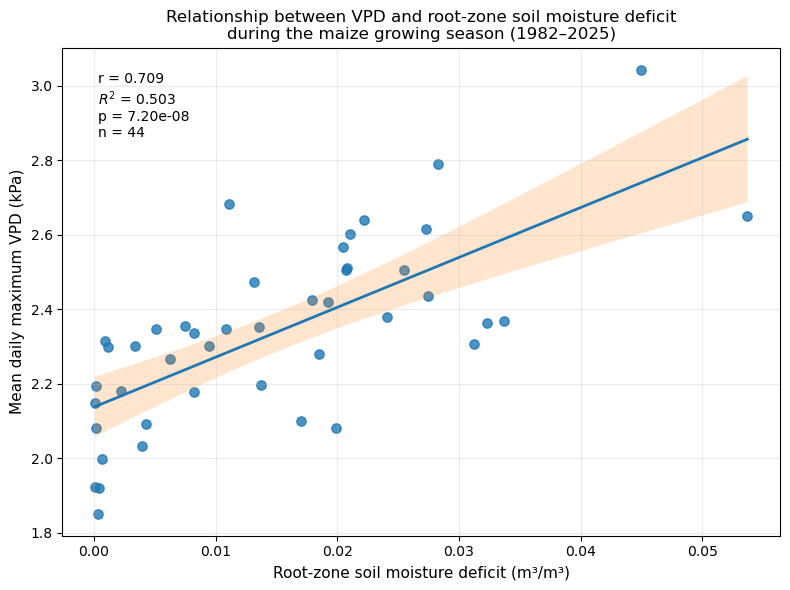

Saved:
C:\Users\franc\vpd_smrz_deficit_relationship_1982_2025.png


In [42]:
# ---------------------------------------------------------
# STEP 7: VPD vs ROOT-ZONE SOIL MOISTURE DEFICIT
# ---------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress, t

# Data
x = smrz_deficit_regional.values
y = vpd_regional.values
years = vpd_regional["harvest_year"].values

valid = np.isfinite(x) & np.isfinite(y)

x = x[valid]
y = y[valid]
years = years[valid]

# Linear regression
result = linregress(x, y)

slope = result.slope
intercept = result.intercept
r = result.rvalue
p = result.pvalue
r_squared = r**2

# Regression line
x_line = np.linspace(x.min(), x.max(), 200)
y_line = intercept + slope * x_line

# ---------------------------------------------------------
# 95% confidence interval around mean regression line
# ---------------------------------------------------------

n = len(x)
y_hat = intercept + slope * x

residuals = y - y_hat
s_err = np.sqrt(
    np.sum(residuals**2) / (n - 2)
)

x_mean = np.mean(x)

t_value = t.ppf(
    0.975,
    df=n - 2
)

confidence = (
    t_value
    * s_err
    * np.sqrt(
        (1 / n)
        +
        ((x_line - x_mean)**2 /
         np.sum((x - x_mean)**2))
    )
)

lower = y_line - confidence
upper = y_line + confidence

# ---------------------------------------------------------
# PLOT
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    x,
    y,
    s=45,
    alpha=0.8
)

ax.plot(
    x_line,
    y_line,
    linewidth=2
)

ax.fill_between(
    x_line,
    lower,
    upper,
    alpha=0.2
)

ax.set_xlabel(
    "Root-zone soil moisture deficit (m³/m³)",
    fontsize=11
)

ax.set_ylabel(
    "Mean daily maximum VPD (kPa)",
    fontsize=11
)

ax.set_title(
    "Relationship between VPD and root-zone soil moisture deficit\n"
    "during the maize growing season (1982–2025)",
    fontsize=12
)

# Statistics
stats_text = (
    f"r = {r:.3f}\n"
    f"$R^2$ = {r_squared:.3f}\n"
    f"p = {p:.2e}\n"
    f"n = {n}"
)

ax.text(
    0.05,
    0.95,
    stats_text,
    transform=ax.transAxes,
    verticalalignment="top",
    fontsize=10
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()

output_file = (
    r"C:\Users\franc"
    r"\vpd_smrz_deficit_relationship_1982_2025.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(output_file)

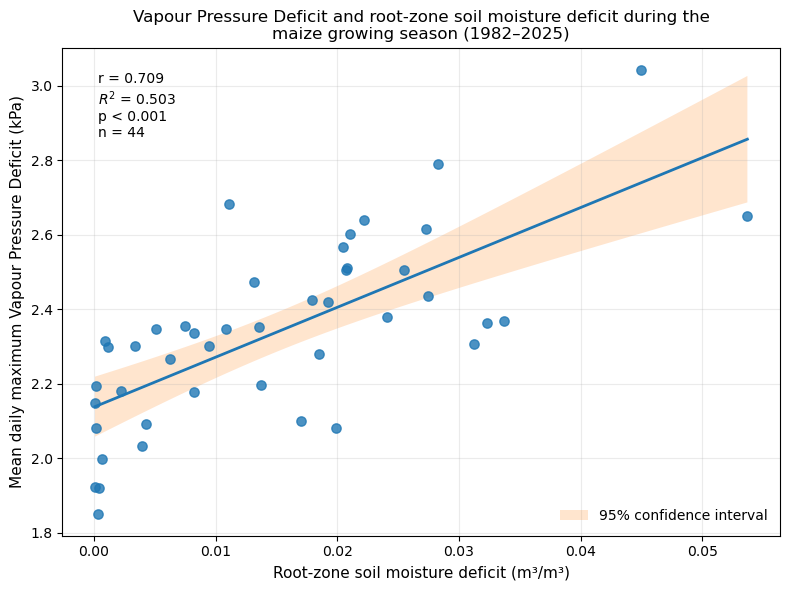

Saved:
C:\Users\franc\vpd_smrz_deficit_relationship_1982_2025_FINAL.png


In [46]:
# ---------------------------------------------------------
# STEP 7B: FINAL THESIS FIGURE
# VPD vs ROOT-ZONE SOIL MOISTURE DEFICIT
# ---------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress, t

# Data
x = smrz_deficit_regional.values
y = vpd_regional.values
years = vpd_regional["harvest_year"].values

valid = np.isfinite(x) & np.isfinite(y)

x = x[valid]
y = y[valid]
years = years[valid]

# ---------------------------------------------------------
# LINEAR REGRESSION
# ---------------------------------------------------------

result = linregress(x, y)

slope = result.slope
intercept = result.intercept
r = result.rvalue
p = result.pvalue
r_squared = r**2

x_line = np.linspace(x.min(), x.max(), 200)
y_line = intercept + slope * x_line

# ---------------------------------------------------------
# 95% CONFIDENCE INTERVAL
# ---------------------------------------------------------

n = len(x)

y_hat = intercept + slope * x
residuals = y - y_hat

s_err = np.sqrt(
    np.sum(residuals**2) / (n - 2)
)

x_mean = np.mean(x)

t_value = t.ppf(
    0.975,
    df=n - 2
)

confidence = (
    t_value
    * s_err
    * np.sqrt(
        (1 / n)
        +
        ((x_line - x_mean)**2 /
         np.sum((x - x_mean)**2))
    )
)

lower = y_line - confidence
upper = y_line + confidence

# ---------------------------------------------------------
# FIGURE
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    x,
    y,
    s=45,
    alpha=0.8,
    zorder=3
)

ax.plot(
    x_line,
    y_line,
    linewidth=2,
    zorder=2
)

ax.fill_between(
    x_line,
    lower,
    upper,
    alpha=0.2,
    label="95% confidence interval",
    zorder=1
)

# ---------------------------------------------------------
# LABEL IMPORTANT CDHW YEARS
# ---------------------------------------------------------

#important_years = [1993, 2002, 2016, 2019, 2024]

#for xi, yi, year in zip(x, y, years):

#    if int(year) in important_years:

#        ax.annotate(
#            str(int(year)),
 #           (xi, yi),
#           xytext=(6, 6),
#            textcoords="offset points",
#            fontsize=9
#        )

# ---------------------------------------------------------
# LABELS
# ---------------------------------------------------------

ax.set_xlabel(
    "Root-zone soil moisture deficit (m³/m³)",
    fontsize=11
)

ax.set_ylabel(
    "Mean daily maximum Vapour Pressure Deficit (kPa)",
    fontsize=11
)

ax.set_title(
    "Vapour Pressure Deficit and root-zone soil moisture deficit during the\n"
    "maize growing season (1982–2025)",
    fontsize=12
)

# Statistics
stats_text = (
    f"r = {r:.3f}\n"
    f"$R^2$ = {r_squared:.3f}\n"
    f"p < 0.001\n"
    f"n = {n}"
)

ax.text(
    0.05,
    0.95,
    stats_text,
    transform=ax.transAxes,
    verticalalignment="top",
    fontsize=10
)

ax.legend(
    loc="lower right",
    frameon=False
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()

# ---------------------------------------------------------
# SAVE PNG
# ---------------------------------------------------------

output_file = (
    r"C:\Users\franc"
    r"\vpd_smrz_deficit_relationship_1982_2025_FINAL.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(output_file)

In [48]:
# ---------------------------------------------------------
# RQ2 STEP 17: FINAL NESTED REGRESSION RESULTS TABLE
# SELF-CONTAINED VERSION
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

# ---------------------------------------------------------
# 1. RELOAD SAVED RQ2 MODELLING DATA
# ---------------------------------------------------------

rq2_file = (
    r"C:\Users\franc"
    r"\rq2_spam_vpd_smrz_yield_1982_2025.csv"
)

rq2_spam_df = pd.read_csv(rq2_file)

print("Dataset loaded:", rq2_spam_df.shape)

# ---------------------------------------------------------
# 2. RECREATE VARIABLES IF NEEDED
# ---------------------------------------------------------

if "VPD_c" not in rq2_spam_df.columns:
    rq2_spam_df["VPD_c"] = (
        rq2_spam_df["VPD"]
        - rq2_spam_df["VPD"].mean()
    )

if "SMrz_deficit_c" not in rq2_spam_df.columns:
    rq2_spam_df["SMrz_deficit_c"] = (
        rq2_spam_df["SMrz_deficit"]
        - rq2_spam_df["SMrz_deficit"].mean()
    )

if "Interaction" not in rq2_spam_df.columns:
    rq2_spam_df["Interaction"] = (
        rq2_spam_df["VPD_c"]
        * rq2_spam_df["SMrz_deficit_c"]
    )

# ---------------------------------------------------------
# 3. FIT FOUR NESTED MODELS
# ---------------------------------------------------------

m1 = smf.ols(
    "MYA ~ SMrz_deficit_c",
    data=rq2_spam_df
).fit()

m2 = smf.ols(
    "MYA ~ VPD_c",
    data=rq2_spam_df
).fit()

m3 = smf.ols(
    "MYA ~ SMrz_deficit_c + VPD_c",
    data=rq2_spam_df
).fit()

m4 = smf.ols(
    "MYA ~ SMrz_deficit_c + VPD_c + Interaction",
    data=rq2_spam_df
).fit()

models = {
    "M1: SM deficit": m1,
    "M2: VPD": m2,
    "M3: Additive": m3,
    "M4: Interaction": m4
}

# ---------------------------------------------------------
# 4. MODEL-LEVEL STATISTICS
# ---------------------------------------------------------

model_rows = []

for name, model in models.items():

    model_rows.append({
        "Model": name,
        "R2": model.rsquared,
        "Adjusted_R2": model.rsquared_adj,
        "AIC": model.aic,
        "BIC": model.bic,
        "F_statistic": model.fvalue,
        "Model_p_value": model.f_pvalue
    })

model_table = pd.DataFrame(model_rows)

# ---------------------------------------------------------
# 5. COEFFICIENT-LEVEL STATISTICS
# ---------------------------------------------------------

coef_rows = []

for name, model in models.items():

    ci = model.conf_int(alpha=0.05)

    for term in model.params.index:

        if term == "Intercept":
            display_term = "Intercept"

        elif term == "VPD_c":
            display_term = "VPD"

        elif term == "SMrz_deficit_c":
            display_term = "SM deficit"

        elif term == "Interaction":
            display_term = "VPD × SM deficit"

        else:
            display_term = term

        coef_rows.append({
            "Model": name,
            "Predictor": display_term,
            "Coefficient": model.params[term],
            "Std_Error": model.bse[term],
            "CI_95_Lower": ci.loc[term, 0],
            "CI_95_Upper": ci.loc[term, 1],
            "t_value": model.tvalues[term],
            "p_value": model.pvalues[term]
        })

coef_table = pd.DataFrame(coef_rows)

# ---------------------------------------------------------
# 6. NESTED TEST: MODEL 3 vs MODEL 4
# ---------------------------------------------------------

nested_test = anova_lm(
    m3,
    m4
)

interaction_F = nested_test.iloc[1]["F"]
interaction_p = nested_test.iloc[1]["Pr(>F)"]

delta_r2 = (
    m4.rsquared
    - m3.rsquared
)

# ---------------------------------------------------------
# 7. DISPLAY RESULTS
# ---------------------------------------------------------

print("\n" + "=" * 72)
print("MODEL-LEVEL STATISTICS")
print("=" * 72)

print(
    model_table
    .round(4)
    .to_string(index=False)
)

print("\n" + "=" * 72)
print("COEFFICIENT ESTIMATES")
print("=" * 72)

print(
    coef_table
    .round(4)
    .to_string(index=False)
)

print("\n" + "=" * 72)
print("ADDITIVE vs INTERACTION MODEL")
print("=" * 72)

print(
    "Incremental R-squared:",
    round(delta_r2, 5)
)

print(
    "F statistic:",
    round(interaction_F, 4)
)

print(
    "p-value:",
    round(interaction_p, 4)
)

# ---------------------------------------------------------
# 8. SAVE FINAL TABLES
# ---------------------------------------------------------

model_output = (
    r"C:\Users\franc"
    r"\rq2_nested_regression_model_statistics_FINAL.csv"
)

coef_output = (
    r"C:\Users\franc"
    r"\rq2_nested_regression_coefficients_FINAL.csv"
)

model_table.to_csv(
    model_output,
    index=False
)

coef_table.to_csv(
    coef_output,
    index=False
)

print("\nSaved:")
print(model_output)
print(coef_output)

Dataset loaded: (44, 8)

MODEL-LEVEL STATISTICS
          Model     R2  Adjusted_R2      AIC      BIC  F_statistic  Model_p_value
 M1: SM deficit 0.0669       0.0447 -19.2767 -15.7083       3.0109         0.0900
        M2: VPD 0.2589       0.2413 -29.4152 -25.8468      14.6746         0.0004
   M3: Additive 0.2941       0.2597 -29.5569 -24.2043       8.5424         0.0008
M4: Interaction 0.2948       0.2419 -27.5979 -20.4612       5.5736         0.0027

COEFFICIENT ESTIMATES
          Model        Predictor  Coefficient  Std_Error  CI_95_Lower  CI_95_Upper  t_value  p_value
 M1: SM deficit        Intercept      -0.0198     0.0287      -0.0776       0.0380  -0.6909   0.4934
 M1: SM deficit       SM deficit      -4.2551     2.4522      -9.2039       0.6937  -1.7352   0.0900
        M2: VPD        Intercept      -0.0198     0.0255      -0.0713       0.0317  -0.7752   0.4425
        M2: VPD              VPD      -0.4627     0.1208      -0.7065      -0.2189  -3.8307   0.0004
   M3: Additiv

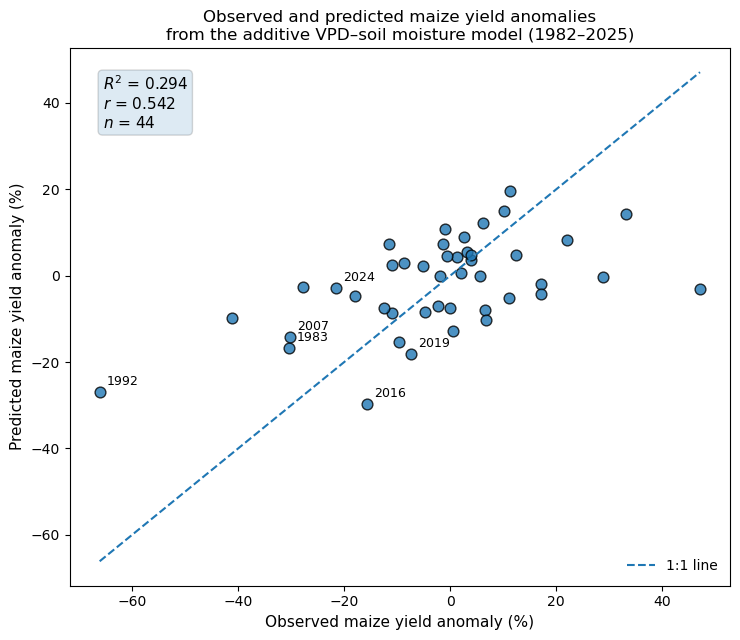

Saved:
C:\Users\franc\rq2_observed_vs_predicted_MYA_FINAL.png


In [49]:
# ---------------------------------------------------------
# RQ2 FINAL PLOT:
# OBSERVED vs PREDICTED MAIZE YIELD ANOMALIES
# Preferred linear additive model
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import pearsonr

# ---------------------------------------------------------
# LOAD SAVED DATA
# ---------------------------------------------------------

rq2_file = (
    r"C:\Users\franc"
    r"\rq2_spam_vpd_smrz_yield_1982_2025.csv"
)

df = pd.read_csv(rq2_file)

# Recreate centred predictors if necessary
if "VPD_c" not in df.columns:
    df["VPD_c"] = (
        df["VPD"] - df["VPD"].mean()
    )

if "SMrz_deficit_c" not in df.columns:
    df["SMrz_deficit_c"] = (
        df["SMrz_deficit"]
        - df["SMrz_deficit"].mean()
    )

# ---------------------------------------------------------
# FIT PREFERRED ADDITIVE MODEL
# ---------------------------------------------------------

model = smf.ols(
    "MYA ~ VPD_c + SMrz_deficit_c",
    data=df
).fit()

# Predictions
df["Predicted_MYA"] = model.predict(df)

# Convert to percentage points
df["Observed_percent"] = df["MYA"] * 100
df["Predicted_percent"] = df["Predicted_MYA"] * 100

# Prediction correlation
r, p = pearsonr(
    df["Observed_percent"],
    df["Predicted_percent"]
)

r2 = model.rsquared

# ---------------------------------------------------------
# PLOT
# ---------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7.5, 6.5)
)

ax.scatter(
    df["Observed_percent"],
    df["Predicted_percent"],
    s=60,
    edgecolor="black",
    alpha=0.8
)

# 1:1 reference line
lower = min(
    df["Observed_percent"].min(),
    df["Predicted_percent"].min()
)

upper = max(
    df["Observed_percent"].max(),
    df["Predicted_percent"].max()
)

ax.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    linewidth=1.5,
    label="1:1 line"
)

# ---------------------------------------------------------
# LABEL IMPORTANT YEARS
# ---------------------------------------------------------

label_years = [
    1983,
    1992,
    2007,
    2016,
    2019,
    2024
]

for year in label_years:

    row = df[
        df["Harvest_Year"] == year
    ]

    if len(row) == 1:

        ax.annotate(
            str(year),
            (
                row["Observed_percent"].iloc[0],
                row["Predicted_percent"].iloc[0]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9
        )

# ---------------------------------------------------------
# STATISTICS
# ---------------------------------------------------------

stats_text = (
    f"$R^2$ = {r2:.3f}\n"
    f"$r$ = {r:.3f}\n"
    f"$n$ = {len(df)}"
)

ax.text(
    0.05,
    0.95,
    stats_text,
    transform=ax.transAxes,
    va="top",
    fontsize=11,
    bbox=dict(
        boxstyle="round",
        alpha=0.15
    )
)

# ---------------------------------------------------------
# LABELS
# ---------------------------------------------------------

ax.set_xlabel(
    "Observed maize yield anomaly (%)",
    fontsize=11
)

ax.set_ylabel(
    "Predicted maize yield anomaly (%)",
    fontsize=11
)

ax.set_title(
    "Observed and predicted maize yield anomalies\n"
    "from the additive VPD–soil moisture model (1982–2025)",
    fontsize=12
)

ax.legend(
    frameon=False
)

plt.tight_layout()

# ---------------------------------------------------------
# SAVE
# ---------------------------------------------------------

output_file = (
    r"C:\Users\franc"
    r"\rq2_observed_vs_predicted_MYA_FINAL.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(output_file)

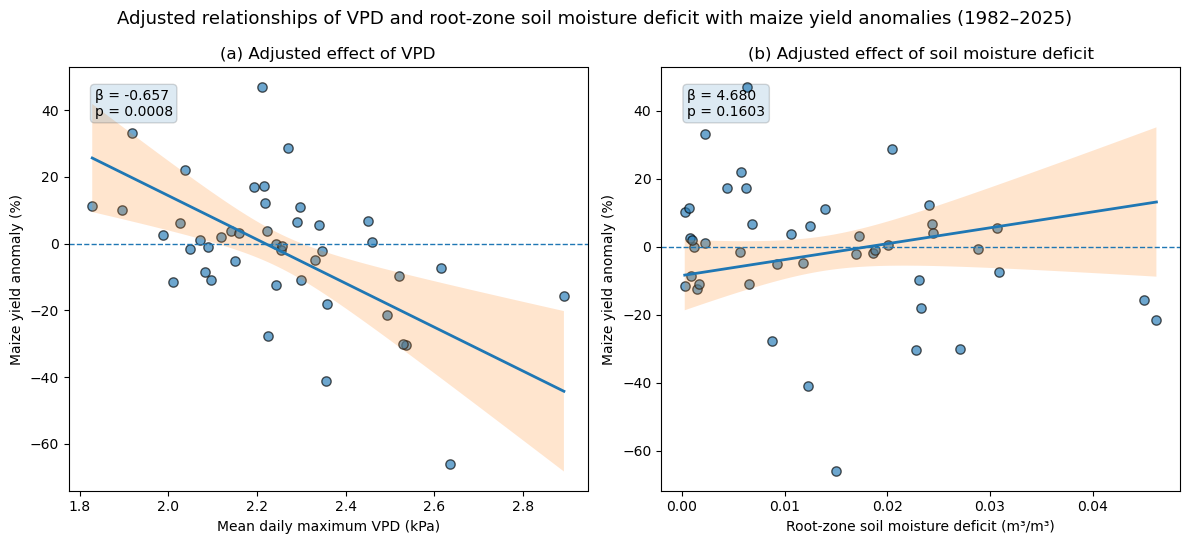

Saved:
C:\Users\franc\rq2_adjusted_vpd_smrz_effects_FINAL.png


In [50]:
# ---------------------------------------------------------
# RQ2 FINAL PLOT:
# ADJUSTED EFFECTS OF VPD AND SOIL MOISTURE DEFICIT
# Preferred additive model
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# ---------------------------------------------------------
# LOAD DATA
# ---------------------------------------------------------

rq2_file = (
    r"C:\Users\franc"
    r"\rq2_spam_vpd_smrz_yield_1982_2025.csv"
)

df = pd.read_csv(rq2_file)

# Recreate centred predictors
df["VPD_c"] = df["VPD"] - df["VPD"].mean()

df["SMrz_deficit_c"] = (
    df["SMrz_deficit"]
    - df["SMrz_deficit"].mean()
)

# ---------------------------------------------------------
# FIT PREFERRED ADDITIVE MODEL
# ---------------------------------------------------------

model = smf.ols(
    "MYA ~ VPD_c + SMrz_deficit_c",
    data=df
).fit()

# =========================================================
# VPD PREDICTION GRID
# Hold soil moisture deficit at its mean
# =========================================================

vpd_values = np.linspace(
    df["VPD"].min(),
    df["VPD"].max(),
    150
)

vpd_prediction_data = pd.DataFrame({
    "VPD_c":
        vpd_values - df["VPD"].mean(),

    "SMrz_deficit_c":
        np.zeros(len(vpd_values))
})

vpd_pred = model.get_prediction(
    vpd_prediction_data
).summary_frame(alpha=0.05)

# =========================================================
# SOIL MOISTURE PREDICTION GRID
# Hold VPD at its mean
# =========================================================

sm_values = np.linspace(
    df["SMrz_deficit"].min(),
    df["SMrz_deficit"].max(),
    150
)

sm_prediction_data = pd.DataFrame({
    "VPD_c":
        np.zeros(len(sm_values)),

    "SMrz_deficit_c":
        sm_values - df["SMrz_deficit"].mean()
})

sm_pred = model.get_prediction(
    sm_prediction_data
).summary_frame(alpha=0.05)

# ---------------------------------------------------------
# FIGURE
# ---------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5.5)
)

# =========================================================
# PANEL A: VPD
# =========================================================

ax = axes[0]

ax.scatter(
    df["VPD"],
    df["MYA_percent"],
    s=45,
    alpha=0.65,
    edgecolor="black"
)

ax.plot(
    vpd_values,
    vpd_pred["mean"].values * 100,
    linewidth=2
)

ax.fill_between(
    vpd_values,
    vpd_pred["mean_ci_lower"].values * 100,
    vpd_pred["mean_ci_upper"].values * 100,
    alpha=0.20
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_xlabel(
    "Mean daily maximum VPD (kPa)"
)

ax.set_ylabel(
    "Maize yield anomaly (%)"
)

ax.set_title(
    "(a) Adjusted effect of VPD"
)

# Statistics
vpd_beta = model.params["VPD_c"]
vpd_p = model.pvalues["VPD_c"]

ax.text(
    0.05,
    0.95,
    (
        f"β = {vpd_beta:.3f}\n"
        f"p = {vpd_p:.4f}"
    ),
    transform=ax.transAxes,
    va="top",
    fontsize=10,
    bbox=dict(
        boxstyle="round",
        alpha=0.15
    )
)

# =========================================================
# PANEL B: SOIL MOISTURE DEFICIT
# =========================================================

ax = axes[1]

ax.scatter(
    df["SMrz_deficit"],
    df["MYA_percent"],
    s=45,
    alpha=0.65,
    edgecolor="black"
)

ax.plot(
    sm_values,
    sm_pred["mean"].values * 100,
    linewidth=2
)

ax.fill_between(
    sm_values,
    sm_pred["mean_ci_lower"].values * 100,
    sm_pred["mean_ci_upper"].values * 100,
    alpha=0.20
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_xlabel(
    "Root-zone soil moisture deficit (m³/m³)"
)

ax.set_ylabel(
    "Maize yield anomaly (%)"
)

ax.set_title(
    "(b) Adjusted effect of soil moisture deficit"
)

# Statistics
sm_beta = model.params["SMrz_deficit_c"]
sm_p = model.pvalues["SMrz_deficit_c"]

ax.text(
    0.05,
    0.95,
    (
        f"β = {sm_beta:.3f}\n"
        f"p = {sm_p:.4f}"
    ),
    transform=ax.transAxes,
    va="top",
    fontsize=10,
    bbox=dict(
        boxstyle="round",
        alpha=0.15
    )
)

# ---------------------------------------------------------
# MAIN TITLE
# ---------------------------------------------------------

fig.suptitle(
    "Adjusted relationships of VPD and root-zone soil moisture deficit "
    "with maize yield anomalies (1982–2025)",
    fontsize=13
)

plt.tight_layout()

# ---------------------------------------------------------
# SAVE
# ---------------------------------------------------------

output_file = (
    r"C:\Users\franc"
    r"\rq2_adjusted_vpd_smrz_effects_FINAL.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(output_file)

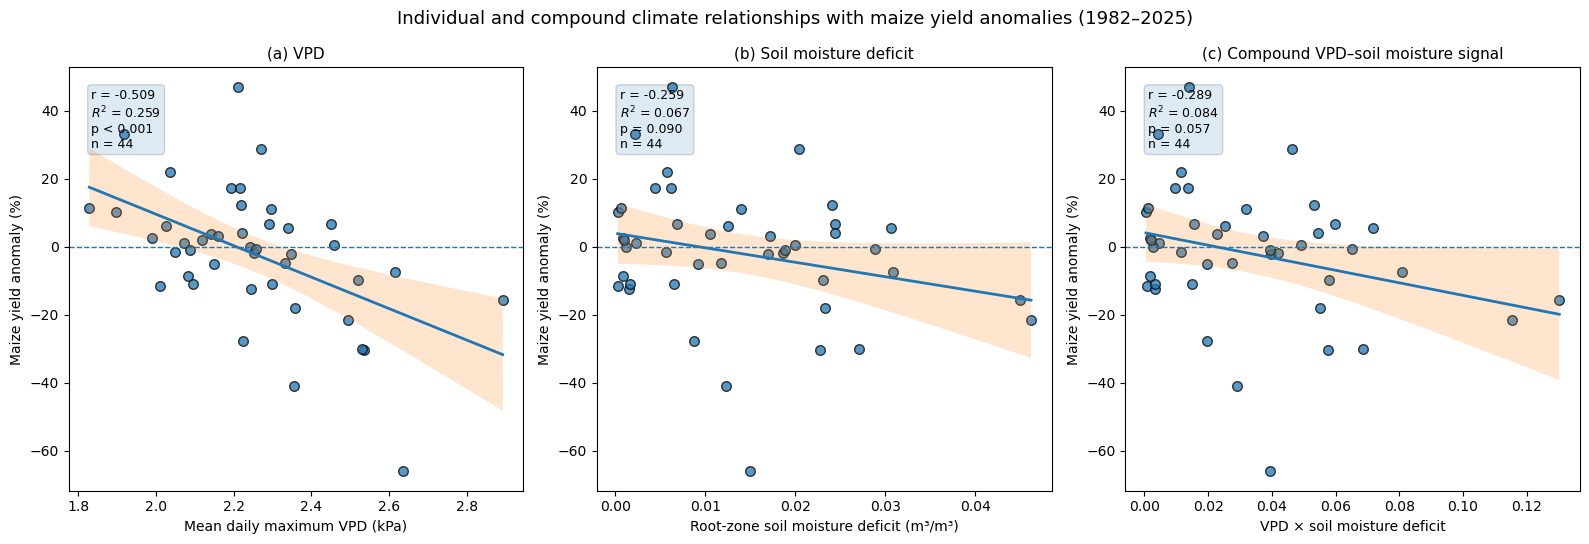

Saved:
C:\Users\franc\rq2_individual_compound_yield_relationships_FINAL.png


In [51]:
# ---------------------------------------------------------
# RQ2: INDIVIDUAL AND COMPOUND CLIMATE–YIELD RELATIONSHIPS
# VPD | Soil moisture deficit | VPD × soil moisture deficit
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import pearsonr
from scipy.stats import t
from scipy.stats import linregress

# ---------------------------------------------------------
# LOAD FINAL SPAM-BASED RQ2 DATA
# ---------------------------------------------------------

file = (
    r"C:\Users\franc"
    r"\rq2_spam_vpd_smrz_yield_1982_2025.csv"
)

df = pd.read_csv(file)

# Raw compound product
df["Compound"] = (
    df["VPD"] *
    df["SMrz_deficit"]
)

# ---------------------------------------------------------
# FUNCTION FOR ONE PANEL
# ---------------------------------------------------------

def relationship_panel(
    ax,
    x,
    y,
    xlabel,
    panel_title
):

    # Remove any non-finite observations
    mask = np.isfinite(x) & np.isfinite(y)

    x = np.asarray(x)[mask]
    y = np.asarray(y)[mask]

    n = len(x)

    # -----------------------------------------------------
    # LINEAR REGRESSION
    # -----------------------------------------------------

    result = linregress(x, y)

    slope = result.slope
    intercept = result.intercept

    # Pearson correlation
    r, p = pearsonr(x, y)

    r2 = r ** 2

    # Prediction grid
    x_grid = np.linspace(
        x.min(),
        x.max(),
        200
    )

    y_fit = (
        intercept
        + slope * x_grid
    )

    # -----------------------------------------------------
    # 95% CONFIDENCE INTERVAL FOR MEAN REGRESSION LINE
    # -----------------------------------------------------

    fitted_obs = (
        intercept
        + slope * x
    )

    residuals = y - fitted_obs

    residual_se = np.sqrt(
        np.sum(residuals ** 2)
        / (n - 2)
    )

    x_mean = np.mean(x)

    Sxx = np.sum(
        (x - x_mean) ** 2
    )

    se_mean = residual_se * np.sqrt(
        (1 / n)
        +
        ((x_grid - x_mean) ** 2 / Sxx)
    )

    tcrit = t.ppf(
        0.975,
        df=n - 2
    )

    lower = y_fit - tcrit * se_mean
    upper = y_fit + tcrit * se_mean

    # -----------------------------------------------------
    # PLOT
    # -----------------------------------------------------

    ax.scatter(
        x,
        y,
        s=48,
        alpha=0.75,
        edgecolor="black"
    )

    ax.plot(
        x_grid,
        y_fit,
        linewidth=2
    )

    ax.fill_between(
        x_grid,
        lower,
        upper,
        alpha=0.20,
        label="95% confidence interval"
    )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_xlabel(
        xlabel,
        fontsize=10
    )

    ax.set_ylabel(
        "Maize yield anomaly (%)",
        fontsize=10
    )

    ax.set_title(
        panel_title,
        fontsize=11
    )

    # -----------------------------------------------------
    # STATISTICS BOX
    # -----------------------------------------------------

    if p < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p:.3f}"

    stats_text = (
        f"r = {r:.3f}\n"
        f"$R^2$ = {r2:.3f}\n"
        f"{p_text}\n"
        f"n = {n}"
    )

    ax.text(
        0.05,
        0.95,
        stats_text,
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        bbox=dict(
            boxstyle="round",
            alpha=0.15
        )
    )

# ---------------------------------------------------------
# CREATE THREE-PANEL FIGURE
# ---------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5.5)
)

# ---------------------------------------------------------
# A: INDIVIDUAL VPD
# ---------------------------------------------------------

relationship_panel(
    axes[0],
    df["VPD"].values,
    df["MYA_percent"].values,
    "Mean daily maximum VPD (kPa)",
    "(a) VPD"
)

# ---------------------------------------------------------
# B: INDIVIDUAL SOIL MOISTURE DEFICIT
# ---------------------------------------------------------

relationship_panel(
    axes[1],
    df["SMrz_deficit"].values,
    df["MYA_percent"].values,
    "Root-zone soil moisture deficit (m³/m³)",
    "(b) Soil moisture deficit"
)

# ---------------------------------------------------------
# C: COMPOUND PRODUCT
# ---------------------------------------------------------

relationship_panel(
    axes[2],
    df["Compound"].values,
    df["MYA_percent"].values,
    "VPD × soil moisture deficit",
    "(c) Compound VPD–soil moisture signal"
)

# ---------------------------------------------------------
# MAIN TITLE
# ---------------------------------------------------------

fig.suptitle(
    "Individual and compound climate relationships with "
    "maize yield anomalies (1982–2025)",
    fontsize=13
)

plt.tight_layout()

# ---------------------------------------------------------
# SAVE PNG
# ---------------------------------------------------------

output_file = (
    r"C:\Users\franc"
    r"\rq2_individual_compound_yield_relationships_FINAL.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(output_file)

In [52]:
# ---------------------------------------------------------
# RQ2 SPATIAL MAPS — STEP 1
# REBUILD 2016 VPD AND SOIL-MOISTURE-DEFICIT FIELDS
# ---------------------------------------------------------

import xarray as xr
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# FILES
# ---------------------------------------------------------

vpd_file = (
    r"C:\Users\franc"
    r"\vpd_daily_max_1981_2025.nc"
)

smrz_file = (
    r"C:\Users\franc"
    r"\SMrz_South_Africa_1981_2025_025deg.nc"
)

# ---------------------------------------------------------
# OPEN DATA
# ---------------------------------------------------------

vpd_ds = xr.open_dataset(
    vpd_file,
    decode_timedelta=False
)

smrz_ds = xr.open_dataset(
    smrz_file,
    decode_timedelta=False
)

# Identify variables
vpd_var = list(vpd_ds.data_vars)[0]
smrz_var = list(smrz_ds.data_vars)[0]

vpd = vpd_ds[vpd_var]
smrz = smrz_ds[smrz_var]

print("VPD variable:", vpd_var)
print("SMrz variable:", smrz_var)

# ---------------------------------------------------------
# OCTOBER–APRIL MAIZE SEASON
# ---------------------------------------------------------

maize_months = [10, 11, 12, 1, 2, 3, 4]

vpd_maize = vpd.where(
    vpd.time.dt.month.isin(maize_months),
    drop=True
)

smrz_maize = smrz.where(
    smrz.time.dt.month.isin(maize_months),
    drop=True
)

# ---------------------------------------------------------
# ASSIGN HARVEST YEAR
#
# Oct–Dec -> following harvest year
# Jan–Apr -> current year
# ---------------------------------------------------------

vpd_harvest_year = xr.where(
    vpd_maize.time.dt.month >= 10,
    vpd_maize.time.dt.year + 1,
    vpd_maize.time.dt.year
)

smrz_harvest_year = xr.where(
    smrz_maize.time.dt.month >= 10,
    smrz_maize.time.dt.year + 1,
    smrz_maize.time.dt.year
)

vpd_maize = vpd_maize.assign_coords(
    harvest_year=("time", vpd_harvest_year.values)
)

smrz_maize = smrz_maize.assign_coords(
    harvest_year=("time", smrz_harvest_year.values)
)

# Keep complete analysis period
vpd_maize = vpd_maize.where(
    (vpd_maize.harvest_year >= 1982) &
    (vpd_maize.harvest_year <= 2025),
    drop=True
)

smrz_maize = smrz_maize.where(
    (smrz_maize.harvest_year >= 1982) &
    (smrz_maize.harvest_year <= 2025),
    drop=True
)

# ---------------------------------------------------------
# SEASONAL MEANS FOR ALL 44 SEASONS
# ---------------------------------------------------------

vpd_seasonal = (
    vpd_maize
    .groupby("harvest_year")
    .mean("time", skipna=True)
)

smrz_seasonal = (
    smrz_maize
    .groupby("harvest_year")
    .mean("time", skipna=True)
)

# ---------------------------------------------------------
# SOIL-MOISTURE DEFICIT
#
# Relative to 1982–2025 Oct–Apr climatology,
# exactly as used in our RQ2 regression.
# ---------------------------------------------------------

smrz_climatology = (
    smrz_seasonal
    .mean("harvest_year", skipna=True)
)

smrz_anomaly = (
    smrz_seasonal
    - smrz_climatology
)

smrz_deficit = xr.where(
    smrz_anomaly < 0,
    -smrz_anomaly,
    0
)

# ---------------------------------------------------------
# SELECT 2016
# ---------------------------------------------------------

vpd_2016 = vpd_seasonal.sel(
    harvest_year=2016
)

smrz_deficit_2016 = smrz_deficit.sel(
    harvest_year=2016
)

# ---------------------------------------------------------
# CHECK
# ---------------------------------------------------------

print("\n2016 VPD shape:")
print(vpd_2016.shape)

print("\n2016 SM deficit shape:")
print(smrz_deficit_2016.shape)

print("\nVPD 2016:")
print(
    "Min =", float(vpd_2016.min(skipna=True)),
    "Mean =", float(vpd_2016.mean(skipna=True)),
    "Max =", float(vpd_2016.max(skipna=True))
)

print("\nSM deficit 2016:")
print(
    "Min =", float(smrz_deficit_2016.min(skipna=True)),
    "Mean =", float(smrz_deficit_2016.mean(skipna=True)),
    "Max =", float(smrz_deficit_2016.max(skipna=True))
)

print("\nLatitude:")
print(
    float(vpd_2016.latitude.values[0]),
    "to",
    float(vpd_2016.latitude.values[-1])
)

print("\nLongitude:")
print(
    float(vpd_2016.longitude.values[0]),
    "to",
    float(vpd_2016.longitude.values[-1])
)

VPD variable: vpd_daily_max
SMrz variable: SMrz

2016 VPD shape:
(57, 89)

2016 SM deficit shape:
(57, 89)

VPD 2016:
Min = 0.7413398526310924 Mean = 3.5580860625581137 Max = 5.064958439671296

SM deficit 2016:
Min = 0.0 Mean = 0.015418689412193562 Max = 0.13573535803637193

Latitude:
-21.0 to -35.0

Longitude:
11.0 to 33.0


In [53]:
# ---------------------------------------------------------
# RQ2 SPATIAL MAPS — STEP 2
# ALIGN SPAM MASK AND VERIFY 2016 AGAINST REGRESSION DATA
# ---------------------------------------------------------

import xarray as xr
import pandas as pd
import numpy as np

# ---------------------------------------------------------
# FILES
# ---------------------------------------------------------

spam_file = (
    r"C:\Users\franc"
    r"\spam2020_sa_maize_mask_cdhw_grid.nc"
)

rq2_file = (
    r"C:\Users\franc"
    r"\rq2_spam_vpd_smrz_yield_1982_2025.csv"
)

# ---------------------------------------------------------
# LOAD SPAM MAIZE AREA
# ---------------------------------------------------------

spam_ds = xr.open_dataset(
    spam_file,
    decode_timedelta=False
)

maize_area = spam_ds["maize_physical_area"]

# Reorder latitude to match climate grid
maize_area = maize_area.sel(
    latitude=vpd_2016.latitude
)

# Maize-growing cells
maize_mask = maize_area > 0

print("Maize-growing cells:")
print(int(maize_mask.sum()))

print("\nLatitude aligned:")
print(
    np.array_equal(
        maize_area.latitude.values,
        vpd_2016.latitude.values
    )
)

print("\nLongitude aligned:")
print(
    np.array_equal(
        maize_area.longitude.values,
        vpd_2016.longitude.values
    )
)

# ---------------------------------------------------------
# APPLY MASK
# ---------------------------------------------------------

vpd_2016_maize = vpd_2016.where(
    maize_mask
)

smrz_2016_maize = smrz_deficit_2016.where(
    maize_mask
)

# Spatial averages over maize-growing cells
vpd_2016_mean = float(
    vpd_2016_maize.mean(
        ["latitude", "longitude"],
        skipna=True
    )
)

smrz_2016_mean = float(
    smrz_2016_maize.mean(
        ["latitude", "longitude"],
        skipna=True
    )
)

# ---------------------------------------------------------
# LOAD SAVED REGRESSION DATA
# ---------------------------------------------------------

rq2_df = pd.read_csv(rq2_file)

saved_2016 = rq2_df.loc[
    rq2_df["Harvest_Year"] == 2016
].iloc[0]

print("\n--------------------------------")
print("2016 RECONSTRUCTED VALUES")
print("--------------------------------")

print("VPD:")
print(vpd_2016_mean)

print("\nSM deficit:")
print(smrz_2016_mean)

print("\n--------------------------------")
print("2016 VALUES USED IN REGRESSION")
print("--------------------------------")

print("VPD:")
print(saved_2016["VPD"])

print("\nSM deficit:")
print(saved_2016["SMrz_deficit"])

# ---------------------------------------------------------
# DIFFERENCE
# ---------------------------------------------------------

print("\n--------------------------------")
print("DIFFERENCE")
print("--------------------------------")

print(
    "VPD difference:",
    vpd_2016_mean - saved_2016["VPD"]
)

print(
    "SM deficit difference:",
    smrz_2016_mean - saved_2016["SMrz_deficit"]
)

spam_ds.close()

Maize-growing cells:
572

Latitude aligned:
True

Longitude aligned:
True

--------------------------------
2016 RECONSTRUCTED VALUES
--------------------------------
VPD:
2.8924896379461917

SM deficit:
0.04502613062513663

--------------------------------
2016 VALUES USED IN REGRESSION
--------------------------------
VPD:
2.892489637946192

SM deficit:
0.0450261306251366

--------------------------------
DIFFERENCE
--------------------------------
VPD difference: -4.440892098500626e-16
SM deficit difference: 2.7755575615628914e-17


C:\Users\franc\AppData\Local\Temp\ipykernel_20688\2817575838.py:203: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


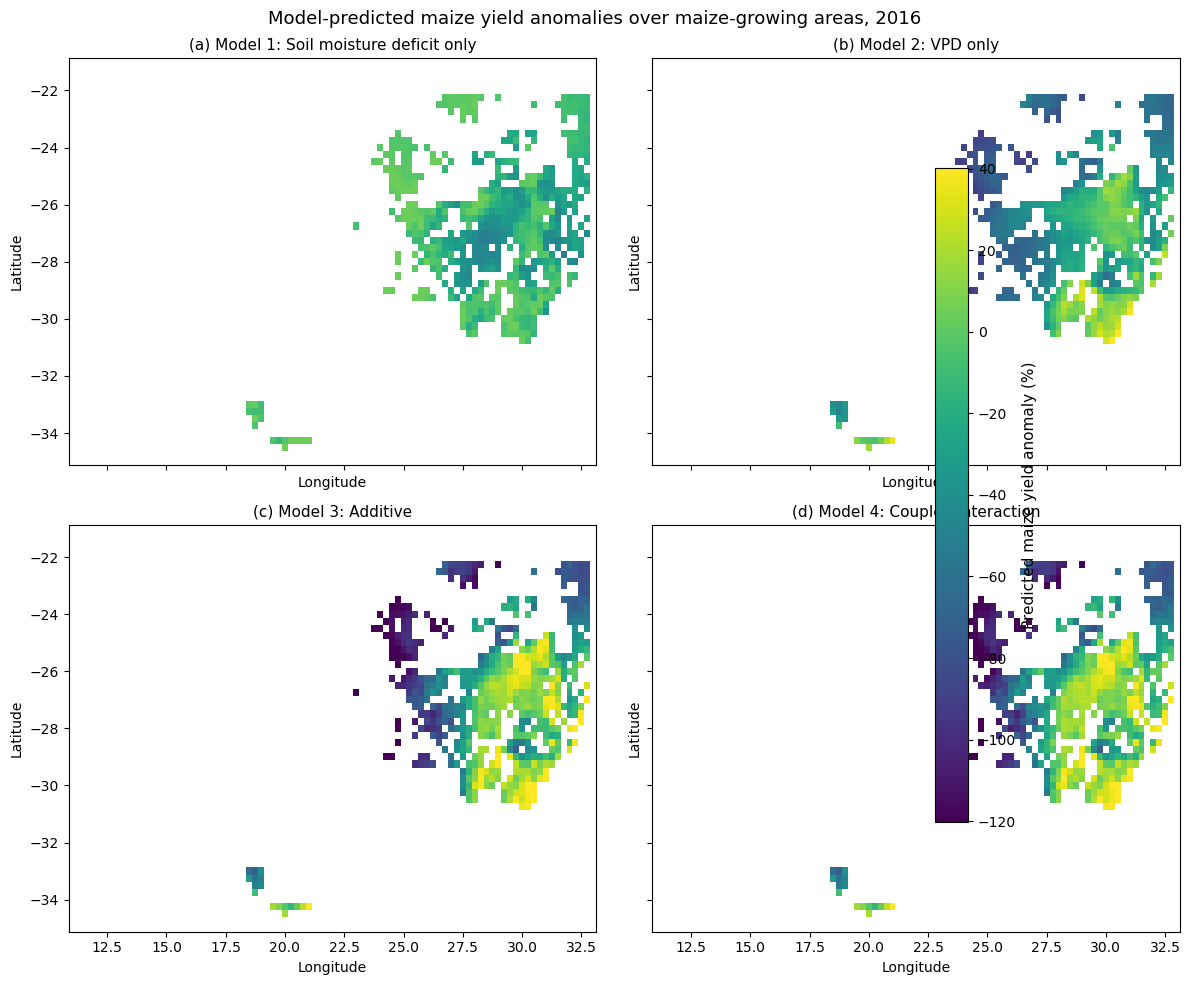

Saved:
C:\Users\franc\rq2_predicted_yield_anomaly_maps_2016_FINAL.png

2016 predicted anomaly ranges:
M1 min = -53.82809994981122 mean = -15.230273332467027 max = 3.9288666218399335
M2 min = -105.23314393459371 mean = -31.74624233422775 max = 43.644360180356074
M3 min = -143.2266305768373 mean = -29.678951121048993 max = 92.5747456988901
M4 min = -143.81896903745573 mean = -28.04508667863113 max = 79.93883583599042


In [55]:
# ---------------------------------------------------------
# RQ2 SPATIAL MAPS — STEP 3
# 2016 PREDICTED MAIZE YIELD ANOMALY MAPS
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# ---------------------------------------------------------
# LOAD SAVED REGRESSION DATA
# ---------------------------------------------------------

rq2_file = (
    r"C:\Users\franc"
    r"\rq2_spam_vpd_smrz_yield_1982_2025.csv"
)

df = pd.read_csv(rq2_file)

# Recreate centred predictors
df["VPD_c"] = df["VPD"] - df["VPD"].mean()

df["SMrz_deficit_c"] = (
    df["SMrz_deficit"]
    - df["SMrz_deficit"].mean()
)

df["Interaction"] = (
    df["VPD_c"]
    * df["SMrz_deficit_c"]
)

# ---------------------------------------------------------
# FIT THE FOUR MODELS
# ---------------------------------------------------------

m1 = smf.ols(
    "MYA ~ SMrz_deficit_c",
    data=df
).fit()

m2 = smf.ols(
    "MYA ~ VPD_c",
    data=df
).fit()

m3 = smf.ols(
    "MYA ~ SMrz_deficit_c + VPD_c",
    data=df
).fit()

m4 = smf.ols(
    "MYA ~ SMrz_deficit_c + VPD_c + Interaction",
    data=df
).fit()

# ---------------------------------------------------------
# GLOBAL MEANS USED FOR CENTERING
# ---------------------------------------------------------

vpd_mean = df["VPD"].mean()
sm_mean = df["SMrz_deficit"].mean()

# ---------------------------------------------------------
# CENTER THE 2016 SPATIAL FIELDS
# ---------------------------------------------------------

vpd_2016_c = (
    vpd_2016_maize
    - vpd_mean
)

sm_2016_c = (
    smrz_2016_maize
    - sm_mean
)

interaction_2016 = (
    vpd_2016_c
    * sm_2016_c
)

# ---------------------------------------------------------
# APPLY REGRESSION EQUATIONS CELL-BY-CELL
# ---------------------------------------------------------

pred_m1_2016 = (
    m1.params["Intercept"]
    +
    m1.params["SMrz_deficit_c"]
    * sm_2016_c
) * 100

pred_m2_2016 = (
    m2.params["Intercept"]
    +
    m2.params["VPD_c"]
    * vpd_2016_c
) * 100

pred_m3_2016 = (
    m3.params["Intercept"]
    +
    m3.params["SMrz_deficit_c"]
    * sm_2016_c
    +
    m3.params["VPD_c"]
    * vpd_2016_c
) * 100

pred_m4_2016 = (
    m4.params["Intercept"]
    +
    m4.params["SMrz_deficit_c"]
    * sm_2016_c
    +
    m4.params["VPD_c"]
    * vpd_2016_c
    +
    m4.params["Interaction"]
    * interaction_2016
) * 100

# ---------------------------------------------------------
# COMMON COLOUR RANGE
# ---------------------------------------------------------

all_values = np.concatenate([
    pred_m1_2016.values[np.isfinite(pred_m1_2016.values)],
    pred_m2_2016.values[np.isfinite(pred_m2_2016.values)],
    pred_m3_2016.values[np.isfinite(pred_m3_2016.values)],
    pred_m4_2016.values[np.isfinite(pred_m4_2016.values)]
])

vmin = np.nanpercentile(all_values, 2)
vmax = np.nanpercentile(all_values, 98)

# ---------------------------------------------------------
# PLOT
# ---------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10),
    sharex=True,
    sharey=True
)

maps = [
    (pred_m1_2016, "(a) Model 1: Soil moisture deficit only"),
    (pred_m2_2016, "(b) Model 2: VPD only"),
    (pred_m3_2016, "(c) Model 3: Additive"),
    (pred_m4_2016, "(d) Model 4: Coupled interaction")
]

for ax, (da, title) in zip(
    axes.flat,
    maps
):

    im = ax.pcolormesh(
        da.longitude,
        da.latitude,
        da,
        shading="auto",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(
        title,
        fontsize=11
    )

    ax.set_xlabel(
        "Longitude"
    )

    ax.set_ylabel(
        "Latitude"
    )

# Shared colourbar
cbar = fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    shrink=0.85
)

cbar.set_label(
    "Predicted maize yield anomaly (%)",
    fontsize=11
)

fig.suptitle(
    "Model-predicted maize yield anomalies over maize-growing areas, 2016",
    fontsize=13
)

plt.tight_layout()

# ---------------------------------------------------------
# SAVE
# ---------------------------------------------------------

output_file = (
    r"C:\Users\franc"
    r"\rq2_predicted_yield_anomaly_maps_2016_FINAL.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(output_file)

# ---------------------------------------------------------
# SUMMARY STATISTICS
# ---------------------------------------------------------

print("\n2016 predicted anomaly ranges:")

for name, da in [
    ("M1", pred_m1_2016),
    ("M2", pred_m2_2016),
    ("M3", pred_m3_2016),
    ("M4", pred_m4_2016)
]:
    print(
        name,
        "min =", float(da.min(skipna=True)),
        "mean =", float(da.mean(skipna=True)),
        "max =", float(da.max(skipna=True))
    )

In [56]:
# ---------------------------------------------------------
# RQ2 SPATIAL MAPS — STEP 4
# CHECK WHETHER 2016 GRID-CELL PREDICTORS ARE EXTRAPOLATING
# BEYOND THE RANGE USED TO FIT THE REGRESSION
# ---------------------------------------------------------

import numpy as np

# ---------------------------------------------------------
# TRAINING RANGES
# These are the 44 SPAM-area averaged seasonal values
# actually used to fit Models 1–4
# ---------------------------------------------------------

train_vpd_min = df["VPD"].min()
train_vpd_max = df["VPD"].max()

train_sm_min = df["SMrz_deficit"].min()
train_sm_max = df["SMrz_deficit"].max()

# ---------------------------------------------------------
# 2016 GRID-CELL VALUES
# ---------------------------------------------------------

vpd_cells = vpd_2016_maize.values
sm_cells = smrz_2016_maize.values

valid = (
    np.isfinite(vpd_cells) &
    np.isfinite(sm_cells)
)

vpd_valid = vpd_cells[valid]
sm_valid = sm_cells[valid]

# ---------------------------------------------------------
# CELLS OUTSIDE TRAINING RANGE
# ---------------------------------------------------------

vpd_out = (
    (vpd_valid < train_vpd_min) |
    (vpd_valid > train_vpd_max)
)

sm_out = (
    (sm_valid < train_sm_min) |
    (sm_valid > train_sm_max)
)

either_out = vpd_out | sm_out

# ---------------------------------------------------------
# PRINT RESULTS
# ---------------------------------------------------------

print("---------------------------------------")
print("REGRESSION TRAINING RANGE")
print("---------------------------------------")

print(
    f"VPD: {train_vpd_min:.4f} to "
    f"{train_vpd_max:.4f} kPa"
)

print(
    f"SM deficit: {train_sm_min:.5f} to "
    f"{train_sm_max:.5f} m3/m3"
)

print("\n---------------------------------------")
print("2016 MAIZE GRID-CELL RANGE")
print("---------------------------------------")

print(
    f"VPD: {vpd_valid.min():.4f} to "
    f"{vpd_valid.max():.4f} kPa"
)

print(
    f"SM deficit: {sm_valid.min():.5f} to "
    f"{sm_valid.max():.5f} m3/m3"
)

print("\n---------------------------------------")
print("EXTRAPOLATION CHECK")
print("---------------------------------------")

print("Valid maize cells:", len(vpd_valid))

print(
    "VPD outside training range:",
    int(vpd_out.sum()),
    f"({100 * vpd_out.mean():.1f}%)"
)

print(
    "SM deficit outside training range:",
    int(sm_out.sum()),
    f"({100 * sm_out.mean():.1f}%)"
)

print(
    "Either predictor outside range:",
    int(either_out.sum()),
    f"({100 * either_out.mean():.1f}%)"
)

# Also check physically problematic predictions
for name, da in [
    ("M1", pred_m1_2016),
    ("M2", pred_m2_2016),
    ("M3", pred_m3_2016),
    ("M4", pred_m4_2016)
]:
    
    values = da.values[np.isfinite(da.values)]
    
    below_minus_100 = np.sum(values < -100)

    print(
        f"\n{name}:",
        f"min = {values.min():.1f}%,",
        f"max = {values.max():.1f}%,",
        f"cells < -100% = {below_minus_100}"
    )

---------------------------------------
REGRESSION TRAINING RANGE
---------------------------------------
VPD: 1.8282 to 2.8925 kPa
SM deficit: 0.00026 to 0.04620 m3/m3

---------------------------------------
2016 MAIZE GRID-CELL RANGE
---------------------------------------
VPD: 1.2632 to 4.4807 kPa
SM deficit: 0.00000 to 0.13574 m3/m3

---------------------------------------
EXTRAPOLATION CHECK
---------------------------------------
Valid maize cells: 572
VPD outside training range: 322 (56.3%)
SM deficit outside training range: 275 (48.1%)
Either predictor outside range: 459 (80.2%)

M1: min = -53.8%, max = 3.9%, cells < -100% = 0

M2: min = -105.2%, max = 43.6%, cells < -100% = 1

M3: min = -143.2%, max = 92.6%, cells < -100% = 72

M4: min = -143.8%, max = 79.9%, cells < -100% = 73
